# Offline failure and early-warning analysis: frozen TF++ on Bench2Drive (schema v2)

This notebook answers seven questions about the 220 Bench2Drive routes run with v2 logging (`results/bench2drive_v2`):

1. **Failure analysis.** Every collision, timed with exact CARLA collision frames, then categorised.
2. **Temporal precursors.** What TF++'s signals do in the 3 s (60 steps) before each collision.
3. **Actor detection.** Did TF++'s predicted boxes cover the actor it later hit, 3, 2 and 1 s before impact?
4. **Geometric analysis.** Surrounding actors rolled forward against TF++'s own planned path: minimum clearance, TTC, and whether the trajectories overlap at the same time.
5. **Safe vs failure.** Crash precursors compared with *successful* junction turns, lane changes, obstacle bypasses and normal driving.
6. **Baselines.** Rules and logistic regression only (no GRU): speed, TF++ confidence, handcrafted temporal instability, current-frame geometry, and current frame + temporal.
7. **Early-warning evaluation.** Event recall ≥1 s and ≥2 s ahead, false alarms per minute, AUROC/AUPRC and lead-time distributions. Cross-validation is grouped by route, thresholds are chosen on validation data only, and confidence intervals come from resampling routes.

The final section summarises the findings, limitations and recommendations.

**Rules followed**

- Monitor features use only what TF++ itself can observe: its planned path, target-speed distribution, controls, ego speed and yaw rate, route command and target point, and its predicted boxes.
- CARLA ground truth (`gt_*`, collision events) is used only for labels, actor matching and offline analysis. Rows that use it are marked **offline reference**.
- TF++ is not modified, no braking is implemented, and no GRU is trained.

**Inputs and code**

- Shared code: [`src/ew_analysis.py`](../src/ew_analysis.py).
- Inputs: `results/bench2drive_v2/{checkpoints,logs}` and `carla_garage/leaderboard/data/bench2drive220.xml`.
- Outputs: `results/bench2drive_v2/early_warning/` (tables as CSV, figures as PNG, and a feature cache).

**Run**

```bash
uv run --no-project --with numpy --with scikit-learn --with matplotlib --with jupyter \
  jupyter nbconvert --to notebook --execute --inplace notebooks/early_warning_analysis.ipynb
```

The first run parses the 1.3 GB of logs, which takes about 10 minutes. Later runs read the cache.

## 0. Setup

In [1]:
import sys, csv, json, math, time, collections
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import ew_analysis as ew

RESULTS = REPO / "results" / "bench2drive_v2"
OUT = RESULTS / "early_warning"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
COL = {"crash": "#c0392b", "junction turn": "#2471a3", "lane change": "#17a589",
       "obstacle bypass": "#b9770e", "normal driving": "#7f8c8d"}

def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

def show_table(rows, cols, fmt=None, headers=None):
    fmt = fmt or {}
    h = headers or cols
    lines = ["| " + " | ".join(h) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        cells = []
        for c in cols:
            v = r.get(c, "")
            cells.append(fmt[c](v) if c in fmt and v != "" else (f"{v:.3g}" if isinstance(v, float) else str(v)))
        lines.append("| " + " | ".join(cells) + " |")
    display(Markdown("\n".join(lines)))

def write_csv(name, rows, cols):
    with open(OUT / f"{name}.csv", "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        w.writerows(rows)

pct = lambda v: f"{100 * v:.0f}%"
ci = lambda lo_hi, f=pct: f"[{f(lo_hi[0])}, {f(lo_hi[1])}]"

In [2]:
t0 = time.time()
routes, ckpts, data = ew.build_cache(RESULTS, REPO / "carla_garage/leaderboard/data/bench2drive220.xml", OUT / "cache.pkl")
feats = {rid: ew.step_features(d) for rid, d in data.items()}
valid = {r: c for r, c in ckpts.items() if c is not None}
fail_routes = {r for r, c in valid.items() if c["failure_kinds"]}
n_steps = sum(d["n"] for d in data.values())
print(f"loaded in {time.time() - t0:.0f} s")
print(f"routes with a result: {len(valid)} of {len(ckpts)} (no result: {[r for r, c in ckpts.items() if c is None]})")
print(f"routes with a failure: {len(fail_routes)} ({len(fail_routes) / len(valid):.1%})")
print(f"logged steps: {n_steps:,} ({n_steps * ew.DT / 3600:.2f} h of driving)")

loaded in 1 s
routes with a result: 219 of 220 (no result: ['11715'])
routes with a failure: 61 (27.9%)
logged steps: 175,264 (2.43 h of driving)


## 1. Failure analysis: every collision, with exact CARLA frames

Collisions come from the per-step `collisions` field, written by a CARLA collision sensor attached to the ego. Each entry carries the simulator frame, the other actor's id and type, and the impulse.

- **Grouping.** Contacts with the same actor less than 1 s apart are merged into one **collision event**. Scraping along a car produces hundreds of consecutive contacts.
- **Counted.** An event is *counted* if the leaderboard also recorded it as an infraction, matched by actor id. Uncounted contacts are mostly kerb or road-surface touches. `static.road` contacts are dropped.
- **Clean history.** An event has a *clean history* if no other contact happened in the 3 s before it. Only these events are used for early warning, so the warning window is not contaminated by an earlier crash.

Each event gets two categories:

- **Situation** (what the ego was doing). Rules applied in order:
  1. pedestrian / cyclist
  2. static object
  3. ego stopped or hit from behind
  4. junction turn / crossing (route command left, right or straight in the last 3 s)
  5. lane change (lane-change command)
  6. obstacle bypass (obstacle-detour scenario)
  7. merge / exit (merge scenario)
  8. rear-end into the vehicle ahead
  9. other
- **Geometry** (how it hit): head-on, crossing, side-swipe or rear-end. Read from the ground-truth heading and position of the other actor 0.1 s before contact.

In [3]:
events = ew.event_table(routes, ckpts, data)
for e in events:
    d = data[e["route"]]
    e["ego_speed"] = round(e["v_pre"], 2)
counted = [e for e in events if e["counted"]]
print(f"distinct contact events (excluding road surface): {len(events)}")
print(f"  counted by the leaderboard: {len(counted)} in {len({e['route'] for e in counted})} routes")
print(f"  not counted (kerb, terrain, minor touches): {len(events) - len(counted)}")
print(f"  counted with a clean 3 s history (used for early warning): {sum(e['clean_history'] for e in counted)}")

# cross-check against the leaderboard: every recorded collision infraction should have a logged event
missing = []
for r, c in valid.items():
    ids = {e["other_id"] for e in counted if e["route"] == r}
    for ce in c["collision_events"]:
        if ce["id"] not in ids and not (ce["id"] == 0 and any(e["route"] == r for e in counted)):
            missing.append((r, ce["type"], ce["id"]))
print(f"leaderboard collision infractions with no matching logged event: {len(missing)} {missing[:5]}")
off_route_only = sorted(r for r in fail_routes if not any(e["route"] == r for e in counted))
print(f"failure routes without a counted collision (off-route only, no timestamp): {off_route_only}")

cols = ["route", "scenario", "family", "time_s", "frame", "other_type", "other_id", "ego_speed", "impulse",
        "duration_s", "situation", "geometry", "counted", "clean_history"]
write_csv("collision_events", events, cols)

distinct contact events (excluding road surface): 88
  counted by the leaderboard: 76 in 56 routes
  not counted (kerb, terrain, minor touches): 12
  counted with a clean 3 s history (used for early warning): 61
leaderboard collision infractions with no matching logged event: 0 []
failure routes without a counted collision (off-route only, no timestamp): ['23658', '23910', '24098', '25896', '2790']


In [4]:
show_table(sorted(counted, key=lambda e: (e["family"], int(e["route"]), e["step"])),
           ["route", "scenario", "time_s", "frame", "other_type", "ego_speed", "situation", "geometry", "clean_history"],
           fmt={"ego_speed": lambda v: f"{v:.1f}", "time_s": lambda v: f"{v:.2f}"},
           headers=["route", "scenario", "time (s)", "CARLA frame", "other actor", "ego speed (m/s)", "situation", "geometry", "clean 3 s"])

| route | scenario | time (s) | CARLA frame | other actor | ego speed (m/s) | situation | geometry | clean 3 s |
|---|---|---|---|---|---|---|---|---|
| 24781 | HardBreakRoute | 4.05 | 22010 | vehicle.mercedes.coupe_2020 | 5.9 | rear-end (lead vehicle) | rear-end (ego hits lead) | True |
| 25358 | StaticCutIn | 196.95 | 17392 | vehicle.ford.crown | 3.2 | rear-end (lead vehicle) | rear-end (ego hits lead) | True |
| 25358 | StaticCutIn | 199.50 | 17443 | vehicle.ford.crown | 0.0 | struck while stopped / from behind | ego stopped | False |
| 26396 | StaticCutIn | 12.80 | 5530 | vehicle.audi.tt | 9.4 | rear-end (lead vehicle) | rear-end (ego hits lead) | True |
| 2050 | SignalizedJunctionRightTurn | 10.30 | 15093 | vehicle.audi.tt | 10.2 | junction turn / crossing | side-swipe | True |
| 2084 | NonSignalizedJunctionLeftTurn | 6.90 | 15991 | vehicle.audi.tt | 10.5 | junction turn / crossing | head-on | True |
| 2091 | NonSignalizedJunctionLeftTurn | 17.70 | 6715 | vehicle.audi.tt | 5.1 | junction turn / crossing | crossing | True |
| 2881 | NonSignalizedJunctionLeftTurn | 6.65 | 15889 | vehicle.chevrolet.impala | 10.4 | junction turn / crossing | head-on | True |
| 3670 | NonSignalizedJunctionRightTurn | 6.50 | 78512 | vehicle.ford.mustang | 9.7 | junction turn / crossing | side-swipe | True |
| 3936 | SignalizedJunctionLeftTurn | 10.05 | 21227 | vehicle.dodge.charger_2020 | 8.9 | junction turn / crossing | head-on | True |
| 4468 | SignalizedJunctionLeftTurn | 9.40 | 26527 | vehicle.ford.mustang | 10.5 | junction turn / crossing | head-on | True |
| 4669 | SignalizedJunctionLeftTurn | 9.50 | 31219 | vehicle.nissan.patrol_2021 | 10.4 | junction turn / crossing | head-on | True |
| 4669 | SignalizedJunctionLeftTurn | 11.00 | 31249 | vehicle.nissan.patrol_2021 | -0.0 | struck while stopped / from behind | ego stopped | False |
| 4683 | SignalizedJunctionLeftTurn | 9.30 | 35446 | vehicle.audi.tt | 9.8 | junction turn / crossing | head-on | True |
| 26950 | OppositeVehicleRunningRedLight | 5.00 | 22858 | vehicle.dodge.charger_police_2020 | 11.3 | junction turn / crossing | head-on | True |
| 26956 | SignalizedJunctionRightTurn | 13.20 | 23671 | vehicle.mercedes.coupe_2020 | 12.0 | junction turn / crossing | crossing | True |
| 26990 | NonSignalizedJunctionLeftTurn | 46.70 | 25686 | vehicle.mercedes.coupe_2020 | 10.2 | junction turn / crossing | head-on | True |
| 27018 | SignalizedJunctionRightTurn | 7.20 | 26525 | vehicle.dodge.charger_2020 | 8.5 | other vehicle conflict | crossing | True |
| 2201 | EnterActorFlow | 49.10 | 11015 | vehicle.mercedes.coupe_2020 | 10.3 | struck while stopped / from behind | rear-ended | True |
| 2283 | MergerIntoSlowTraffic | 3.95 | 14732 | vehicle.dodge.charger_2020 | 15.6 | lane change | side-swipe | True |
| 3048 | MergerIntoSlowTraffic | 4.15 | 20488 | vehicle.lincoln.mkz_2020 | 8.4 | lane change | side-swipe | True |
| 3785 | MergerIntoSlowTraffic | 3.65 | 88345 | vehicle.dodge.charger_2020 | 13.6 | lane change | side-swipe | True |
| 3800 | MergerIntoSlowTraffic | 3.60 | 88949 | vehicle.lincoln.mkz_2020 | 14.9 | lane change | side-swipe | True |
| 3800 | MergerIntoSlowTraffic | 6.40 | 89005 | vehicle.lincoln.mkz_2020 | 13.6 | junction turn / crossing | side-swipe | False |
| 11755 | EnterActorFlow | 17.20 | 1649 | vehicle.nissan.patrol_2021 | 9.7 | junction turn / crossing | crossing | True |
| 17569 | SequentialLaneChange | 8.10 | 5247 | vehicle.mercedes.coupe_2020 | 16.5 | lane change | rear-end (ego hits lead) | True |
| 17569 | SequentialLaneChange | 13.95 | 5364 | vehicle.audi.tt | 14.9 | lane change | side-swipe | True |
| 17569 | SequentialLaneChange | 14.50 | 5375 | vehicle.lincoln.mkz_2017 | 11.4 | lane change | rear-end (ego hits lead) | False |
| 17655 | SequentialLaneChange | 10.45 | 9761 | vehicle.ford.mustang | 17.5 | lane change | side-swipe | True |
| 23659 | HighwayExit | 8.90 | 14313 | vehicle.dodge.charger_2020 | 4.3 | merge / exit | side-swipe | True |
| 23659 | HighwayExit | 67.20 | 15479 | vehicle.dodge.charger_2020 | 0.0 | struck while stopped / from behind | ego stopped | True |
| 23659 | HighwayExit | 102.35 | 16182 | static.pole | 8.4 | static object | static object | False |
| 23670 | HighwayExit | 3.70 | 22971 | vehicle.dodge.charger_2020 | 11.4 | junction turn / crossing | side-swipe | True |
| 23687 | HighwayExit | 3.75 | 23585 | vehicle.mercedes.coupe_2020 | 11.7 | junction turn / crossing | side-swipe | True |
| 23771 | MergerIntoSlowTrafficV2 | 8.55 | 25501 | vehicle.mercedes.coupe_2020 | 0.6 | struck while stopped / from behind | ego stopped | True |
| 23901 | InterurbanActorFlow | 16.80 | 2586 | static.terrain | 11.4 | static object | static object | True |
| 23901 | InterurbanActorFlow | 86.25 | 3975 | static.terrain | 0.0 | static object | static object | True |
| 23901 | InterurbanActorFlow | 137.95 | 5009 | static.terrain | 0.0 | static object | static object | True |
| 23901 | InterurbanActorFlow | 140.90 | 5068 | static.terrain | 0.0 | static object | static object | False |
| 23918 | InterurbanActorFlow | 4.60 | 6938 | vehicle.lincoln.mkz_2020 | 13.5 | junction turn / crossing | rear-end (ego hits lead) | True |
| 24092 | MergerIntoSlowTrafficV2 | 8.05 | 10280 | vehicle.lincoln.mkz_2017 | 17.8 | junction turn / crossing | side-swipe | True |
| 1790 | HazardAtSideLane | 9.85 | 1982 | vehicle.ford.mustang | 9.8 | obstacle bypass | rear-end (ego hits lead) | True |
| 1792 | HazardAtSideLane | 5.40 | 2301 | vehicle.audi.tt | 18.7 | obstacle bypass | rear-end (ego hits lead) | True |
| 1825 | ConstructionObstacleTwoWays | 13.40 | 3043 | vehicle.chevrolet.impala | 11.1 | obstacle bypass | head-on | True |
| 1833 | ConstructionObstacleTwoWays | 25.20 | 5822 | static.prop.constructioncone | 12.0 | static object | static object | True |
| 1833 | ConstructionObstacleTwoWays | 25.80 | 5834 | static.prop.constructioncone | 9.0 | static object | static object | False |
| 1852 | AccidentTwoWays | 26.20 | 6821 | vehicle.dodge.charger_police_2020 | 12.3 | obstacle bypass | side-swipe | True |
| 2509 | ConstructionObstacle | 5.15 | 18584 | vehicle.audi.tt | 10.8 | obstacle bypass | side-swipe | True |
| 2534 | Accident | 5.00 | 19385 | vehicle.ford.mustang | 16.1 | obstacle bypass | side-swipe | True |
| 2606 | ConstructionObstacleTwoWays | 25.15 | 47006 | static.prop.dirtdebris02 | 11.2 | static object | static object | True |
| 2606 | ConstructionObstacleTwoWays | 25.65 | 47016 | static.prop.constructioncone | 9.1 | static object | static object | False |
| 2606 | ConstructionObstacleTwoWays | 25.70 | 47017 | static.prop.constructioncone | 9.3 | static object | static object | False |
| 2606 | ConstructionObstacleTwoWays | 27.15 | 47046 | static.prop.constructioncone | 7.7 | static object | static object | False |
| 2643 | AccidentTwoWays | 13.70 | 8526 | vehicle.nissan.patrol_2021 | 11.0 | obstacle bypass | head-on | True |
| 2664 | ParkedObstacleTwoWays | 12.30 | 10833 | vehicle.dodge.charger_police_2020 | 9.8 | obstacle bypass | side-swipe | True |
| 2802 | InvadingTurn | 6.35 | 14239 | vehicle.audi.tt | 9.7 | obstacle bypass | rear-end (ego hits lead) | True |
| 3472 | VehicleOpensDoorTwoWays | 7.80 | 9769 | vehicle.dodge.charger_police_2020 | 7.2 | obstacle bypass | side-swipe | True |
| 3482 | VehicleOpensDoorTwoWays | 7.80 | 10760 | vehicle.chevrolet.impala | 19.1 | obstacle bypass | side-swipe | True |
| 3482 | VehicleOpensDoorTwoWays | 10.20 | 10808 | vehicle.mercedes.coupe_2020 | 19.9 | obstacle bypass | side-swipe | False |
| 3564 | InvadingTurn | 6.80 | 13722 | static.prop.mesh | 10.8 | static object | static object | True |
| 3564 | InvadingTurn | 7.25 | 13731 | static.prop.mesh | 9.9 | static object | static object | False |
| 3564 | InvadingTurn | 12.20 | 13830 | static.prop.mesh | 4.8 | static object | static object | False |
| 3564 | InvadingTurn | 16.90 | 13924 | static.prop.mesh | 9.3 | static object | static object | False |
| 20920 | ConstructionObstacleTwoWays | 24.90 | 13247 | static.prop.constructioncone | 13.3 | static object | static object | True |
| 24795 | ConstructionObstacle | 5.45 | 3489 | vehicle.dodge.charger_2020 | 8.6 | obstacle bypass | side-swipe | True |
| 25383 | ParkedObstacle | 5.55 | 24251 | vehicle.nissan.patrol_2021 | 10.1 | obstacle bypass | side-swipe | True |
| 25424 | ConstructionObstacleTwoWays | 9.15 | 25813 | vehicle.chevrolet.impala | 13.5 | obstacle bypass | head-on | True |
| 25439 | HazardAtSideLane | 6.30 | 26805 | vehicle.nissan.patrol_2021 | 7.2 | obstacle bypass | side-swipe | True |
| 25439 | HazardAtSideLane | 61.80 | 27915 | vehicle.nissan.patrol_2021 | 0.0 | struck while stopped / from behind | ego stopped | True |
| 25857 | AccidentTwoWays | 8.20 | 33987 | vehicle.mini.cooper_s_2021 | 12.7 | obstacle bypass | head-on | True |
| 25857 | AccidentTwoWays | 100.90 | 35841 | vehicle.lincoln.mkz_2017 | 8.3 | obstacle bypass | head-on | False |
| 3255 | ParkingCrossingPedestrian | 8.70 | 10348 | walker.pedestrian.0039 | 0.4 | pedestrian / cyclist | pedestrian | True |
| 3731 | VehicleTurningRoutePedestrian | 34.90 | 11324 | walker.pedestrian.0011 | 7.6 | pedestrian / cyclist | pedestrian | True |
| 24206 | ParkingCrossingPedestrian | 5.90 | 11212 | walker.pedestrian.0039 | 10.9 | pedestrian / cyclist | pedestrian | True |
| 24211 | DynamicObjectCrossing | 5.80 | 12311 | walker.pedestrian.0011 | 14.0 | pedestrian / cyclist | pedestrian | True |
| 24224 | DynamicObjectCrossing | 5.50 | 13026 | walker.pedestrian.0011 | 16.0 | pedestrian / cyclist | pedestrian | True |

| situation | events | share | median ego speed (m/s) | geometry | top scenarios |
|---|---|---|---|---|---|
| junction turn / crossing | 18 | 24% | 10.4 | head-on 8, side-swipe 6, crossing 3, rear-end (ego hits lead) 1 | NonSignalizedJunctionLeftTurn (4), SignalizedJunctionLeftTurn (4), SignalizedJunctionRightTurn (2) |
| obstacle bypass | 18 | 24% | 10.9 | side-swipe 10, head-on 5, rear-end (ego hits lead) 3 | AccidentTwoWays (4), HazardAtSideLane (3), VehicleOpensDoorTwoWays (3) |
| static object | 16 | 21% | 9.2 | static object 16 | ConstructionObstacleTwoWays (7), InterurbanActorFlow (4), InvadingTurn (4) |
| lane change | 8 | 11% | 14.9 | side-swipe 6, rear-end (ego hits lead) 2 | SequentialLaneChange (4), MergerIntoSlowTraffic (4) |
| struck while stopped / from behind | 6 | 8% | 0.0 | ego stopped 5, rear-ended 1 | EnterActorFlow (1), HighwayExit (1), MergerIntoSlowTrafficV2 (1) |
| pedestrian / cyclist | 5 | 7% | 10.9 | pedestrian 5 | ParkingCrossingPedestrian (2), DynamicObjectCrossing (2), VehicleTurningRoutePedestrian (1) |
| rear-end (lead vehicle) | 3 | 4% | 5.9 | rear-end (ego hits lead) 3 | StaticCutIn (2), HardBreakRoute (1) |
| merge / exit | 1 | 1% | 4.3 | side-swipe 1 | HighwayExit (1) |
| other vehicle conflict | 1 | 1% | 8.5 | crossing 1 | SignalizedJunctionRightTurn (1) |

| family | routes | failed routes | failure rate | counted collisions | mean driving score |
|---|---|---|---|---|---|
| junction | 75 | 13 | 17% | 14 | 84.3 |
| lane_merge | 39 | 18 | 46% | 23 | 74.2 |
| obstacle_detour | 50 | 22 | 44% | 30 | 70.2 |
| cut_in_hazard | 30 | 3 | 10% | 4 | 84.2 |
| vru_crossing | 25 | 5 | 20% | 5 | 80.4 |

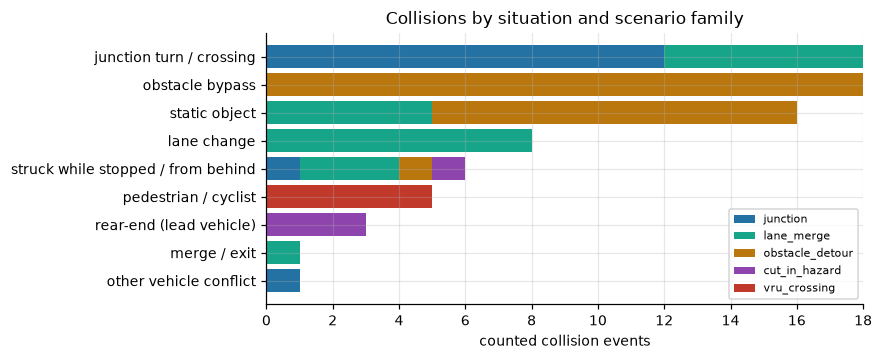

In [5]:
sits = collections.Counter(e["situation"] for e in counted)
rows = []
for s, n in sits.most_common():
    es = [e for e in counted if e["situation"] == s]
    rows.append({"situation": s, "events": n, "share": n / len(counted),
                 "median ego speed (m/s)": float(np.median([e["ego_speed"] for e in es])),
                 "geometry": ", ".join(f"{g} {k}" for g, k in collections.Counter(e["geometry"] for e in es).most_common()),
                 "top scenarios": ", ".join(f"{g} ({k})" for g, k in collections.Counter(e["scenario"] for e in es).most_common(3))})
show_table(rows, list(rows[0]), fmt={"share": pct, "median ego speed (m/s)": lambda v: f"{v:.1f}"})
write_csv("collision_situations", rows, list(rows[0]))

fams = ["junction", "lane_merge", "obstacle_detour", "cut_in_hazard", "vru_crossing"]
fam_rows = []
for f in fams:
    rs = [r for r in valid if routes[r]["family"] == f]
    fam_rows.append({"family": f, "routes": len(rs), "failed routes": sum(r in fail_routes for r in rs),
                     "failure rate": sum(r in fail_routes for r in rs) / len(rs),
                     "counted collisions": sum(e["family"] == f for e in counted),
                     "mean driving score": float(np.mean([valid[r]["ds"] for r in rs]))})
show_table(fam_rows, list(fam_rows[0]), fmt={"failure rate": pct, "mean driving score": lambda v: f"{v:.1f}"})

fig, ax = plt.subplots(figsize=(7, 3.2))
labels = [s for s, _ in sits.most_common()][::-1]
left = np.zeros(len(labels))
for f, c in zip(fams, ["#2471a3", "#17a589", "#b9770e", "#8e44ad", "#c0392b"]):
    vals = np.array([sum(1 for e in counted if e["situation"] == s and e["family"] == f) for s in labels])
    ax.barh(labels, vals, left=left, color=c, label=f)
    left += vals
ax.set_xlabel("counted collision events"); ax.legend(fontsize=7, loc="lower right"); ax.set_title("Collisions by situation and scenario family")
savefig("01_collisions_by_situation"); plt.show()

## 2. Temporal precursors: the 60 steps before each collision

The windows are the 60 steps (3 s) before each counted collision with a clean history. They are compared with windows of the same length that end at the peak of **successful** manoeuvres: junction turns, lane changes and obstacle bypasses with no contact within 8 s before or 5 s after, plus normal lane following.

Signals:

- **Path disagreement** (1 s mean): the distance between TF++'s current path and its previous path, after shifting the previous path for the ego's own motion.
- **Target-speed JS divergence** (1 s mean): how much TF++'s speed distribution changes from one step to the next.
- **Steering variation** (1 s total variation).
- **Brake**, **ego speed** and **speed-head entropy**.
- **Geometric risk on TF++'s path** (3 s minus TTC): TF++'s predicted boxes against its own planned path.
- **Offline reference:** the same geometric risk computed with ground-truth actors.

safe manoeuvre windows: Counter({'normal driving': 538, 'junction turn': 54, 'obstacle bypass': 28, 'lane change': 7})
crash windows (counted, clean history, >= 3 s of log): 61


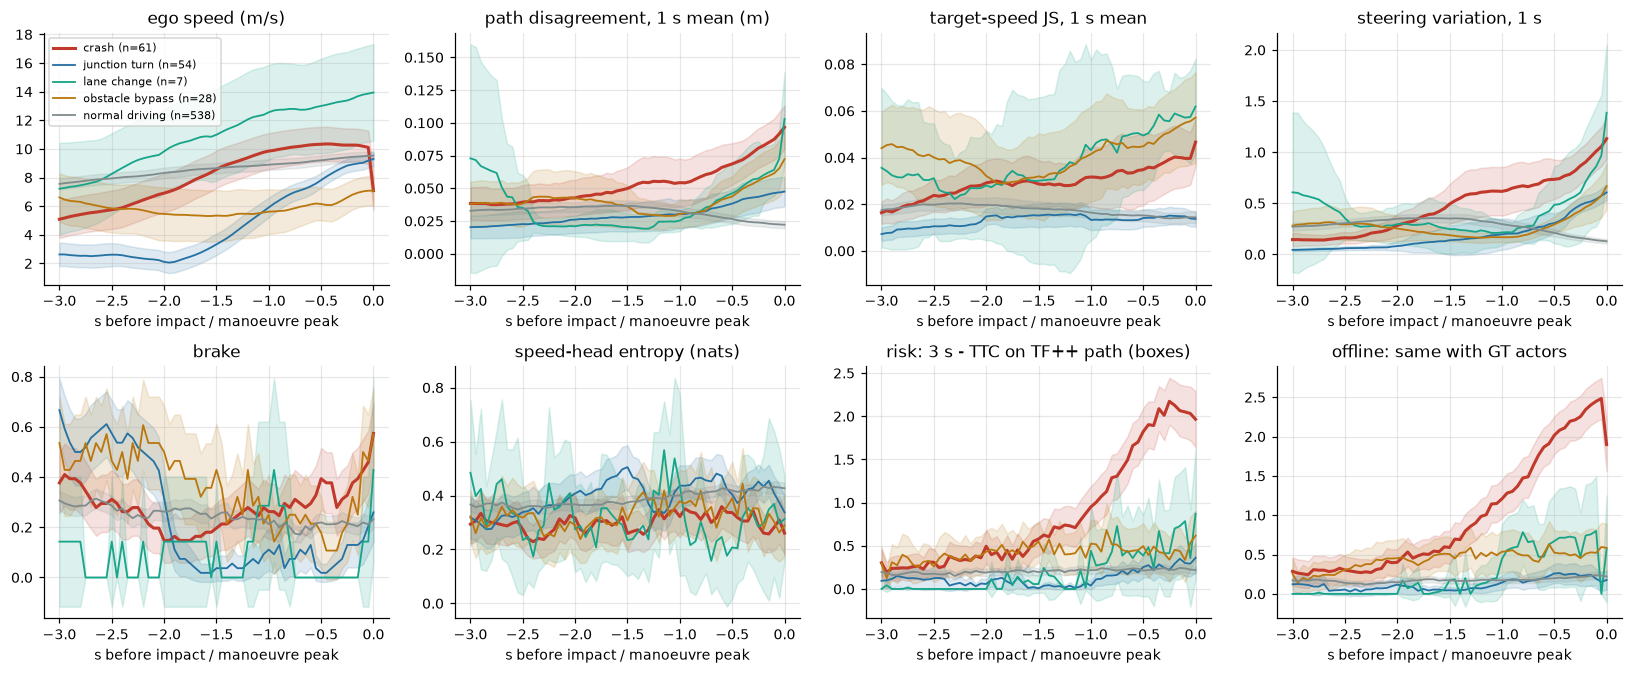

In [6]:
W = 60
anchors = ew.maneuver_anchors(routes, data, events)
print("safe manoeuvre windows:", collections.Counter(a["label"] for a in anchors))
crash = [e for e in counted if e["clean_history"] and e["step"] >= W]
print("crash windows (counted, clean history, >= 3 s of log):", len(crash))

SIG = [("ego_speed", "ego speed (m/s)"), ("path_disagree_mean_1s", "path disagreement, 1 s mean (m)"),
       ("speed_js_mean_1s", "target-speed JS, 1 s mean"), ("steer_tv_1s", "steering variation, 1 s"),
       ("brake", "brake"), ("speed_entropy", "speed-head entropy (nats)"),
       ("risk_plan", "risk: 3 s - TTC on TF++ path (boxes)"), ("gt_risk_plan", "offline: same with GT actors")]

def window(rid, end, key, w=W):
    x = feats[rid][key]
    lo = end - w
    if lo < 0:
        return None
    return x[lo:end + 1]

def traces(items, key):
    out = [window(it["route"], it["step"], key) for it in items]
    return np.array([o for o in out if o is not None and len(o) == W + 1])

groups = {"crash": crash, **{lab: [a for a in anchors if a["label"] == lab] for lab in
                             ("junction turn", "lane change", "obstacle bypass", "normal driving")}}
tt = np.arange(-W, 1) * ew.DT
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for ax, (key, title) in zip(axes.flat, SIG):
    for lab, items in groups.items():
        A = traces(items, key)
        if len(A) == 0:
            continue
        m, se = A.mean(0), A.std(0) / np.sqrt(len(A))
        ax.plot(tt, m, color=COL[lab], lw=2 if lab == "crash" else 1.2, label=f"{lab} (n={len(A)})")
        ax.fill_between(tt, m - 1.96 * se, m + 1.96 * se, color=COL[lab], alpha=0.15)
    ax.set_title(title); ax.set_xlabel("s before impact / manoeuvre peak")
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); savefig("02_precursors_vs_safe_manoeuvres"); plt.show()

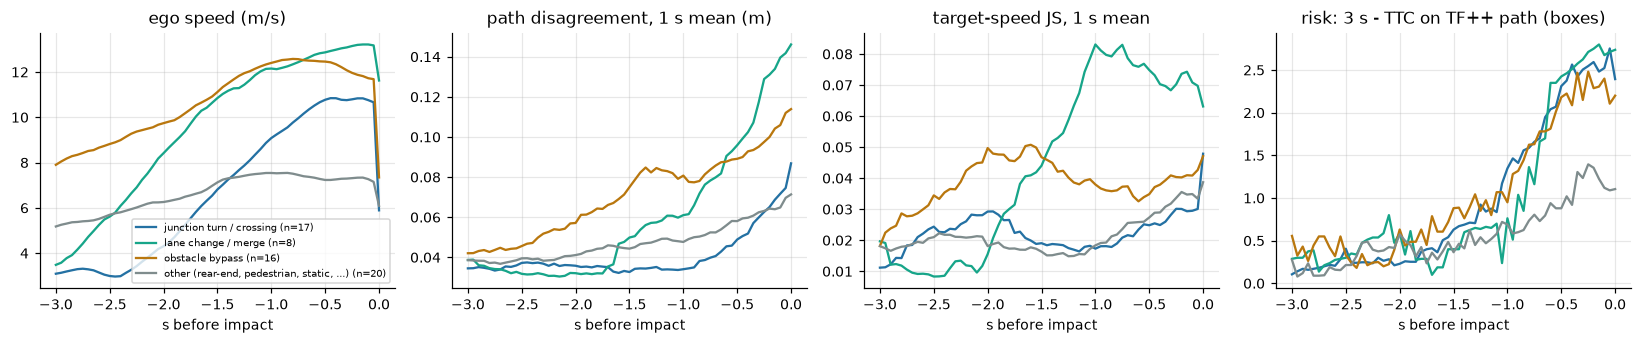

In [7]:
SIT_GROUPS = {"junction turn / crossing": ["junction turn / crossing"],
              "lane change / merge": ["lane change", "merge / exit"],
              "obstacle bypass": ["obstacle bypass"],
              "other (rear-end, pedestrian, static, ...)": None}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (key, title) in zip(axes, [SIG[0], SIG[1], SIG[2], SIG[6]]):
    for (lab, sits_), c in zip(SIT_GROUPS.items(), ["#2471a3", "#17a589", "#b9770e", "#7f8c8d"]):
        items = [e for e in crash if (e["situation"] in sits_ if sits_ else
                                      e["situation"] not in sum([v for v in SIT_GROUPS.values() if v], []))]
        A = traces(items, key)
        if len(A):
            ax.plot(tt, A.mean(0), color=c, label=f"{lab} (n={len(A)})")
    ax.set_title(title); ax.set_xlabel("s before impact")
axes[0].legend(fontsize=6.5)
plt.tight_layout(); savefig("02b_precursors_by_situation"); plt.show()

**When does each signal first become unusual?** For every crash window, the onset is the start of the signal's final continuous run (gaps up to 0.25 s allowed) above the **95th percentile of normal moving driving** (below the 5th percentile for entropy). For the geometric signals the onset is the first time TTC on the planned path drops below 3 s.

This is a descriptive analysis. The percentile thresholds are not validated, and Section 7 gives the proper evaluation.

In [8]:
normal_vals = {}
for key, _ in SIG:
    v = np.concatenate([feats[a["route"]][key][max(0, a["step"] - 200): a["step"] + 200] for a in groups["normal driving"]])
    normal_vals[key] = v
def onset(x, above):
    a = x > above if np.isfinite(above) else x > 0
    if not a[-3:].any():
        return 0.0
    idx = np.where(a)[0]
    start = idx[-1]
    for k in idx[::-1][1:]:
        if start - k <= 5:
            start = k
        else:
            break
    return (len(x) - 1 - start) * ew.DT

rows = []
for key, title in SIG:
    if key == "brake":
        continue
    if key in ("risk_plan", "gt_risk_plan"):
        thr, sign = 0.0, 1
    elif key == "speed_entropy":
        thr, sign = -np.quantile(normal_vals[key], 0.05), -1
    else:
        thr, sign = np.quantile(normal_vals[key], 0.95), 1
    A = traces(crash, key) * sign
    ons = np.array([onset(a, thr) for a in A])
    nrm = normal_vals[key] * sign
    rows.append({"signal": title, "threshold": abs(thr), "crashes flagged at all": (ons > 0).mean(),
                 "onset >= 1 s": (ons >= 1).mean(), "onset >= 2 s": (ons >= 2).mean(),
                 "median onset (s, flagged only)": float(np.median(ons[ons > 0])) if (ons > 0).any() else float("nan"),
                 "normal driving above threshold": float((nrm > thr).mean())})
show_table(rows, list(rows[0]), fmt={k: pct for k in ["crashes flagged at all", "onset >= 1 s", "onset >= 2 s", "normal driving above threshold"]}
           | {"threshold": lambda v: f"{v:.3g}", "median onset (s, flagged only)": lambda v: f"{v:.2f}"})
write_csv("precursor_onsets", rows, list(rows[0]))

| signal | threshold | crashes flagged at all | onset >= 1 s | onset >= 2 s | median onset (s, flagged only) | normal driving above threshold |
|---|---|---|---|---|---|---|
| ego speed (m/s) | 14.8 | 16% | 11% | 5% | 1.23 | 5% |
| path disagreement, 1 s mean (m) | 0.127 | 26% | 10% | 7% | 0.70 | 5% |
| target-speed JS, 1 s mean | 0.0747 | 20% | 7% | 2% | 0.60 | 5% |
| steering variation, 1 s | 0.981 | 49% | 16% | 3% | 0.45 | 5% |
| speed-head entropy (nats) | 0.000261 | 10% | 2% | 2% | 0.48 | 5% |
| risk: 3 s - TTC on TF++ path (boxes) | 0 | 84% | 57% | 18% | 1.40 | 20% |
| offline: same with GT actors | 0 | 87% | 61% | 30% | 1.50 | 19% |

## 3. Did TF++ detect the actor it hit?

For each counted collision with a vehicle or pedestrian, every step in the 6 s before impact is checked: was the struck ground-truth actor matched by a TF++ predicted box?

- **Match rule:** same class (car or emergency vehicle for vehicles, walker for pedestrians), box centre within 3 m (2 m for pedestrians).
- **Box range:** TF++ only predicts boxes within ±32 m, so an actor outside that is *out of range*, not *missed*.
- **Dropouts:** a box that disappears and later reappears while the actor stays in range.

collisions with a vehicle or pedestrian: 60


| time before impact | detected | missed | out of box range (>32 m) | not logged | detection rate when in range |
|---|---|---|---|---|---|
| 3 s | 31 | 3 | 19 | 7 | 91% |
| 2 s | 45 | 3 | 8 | 4 | 94% |
| 1 s | 59 | 1 | 0 | 0 | 98% |
| 0.5 s | 58 | 2 | 0 | 0 | 97% |

Text(0.5, 1.0, 'Median box-to-GT centre error (m)')

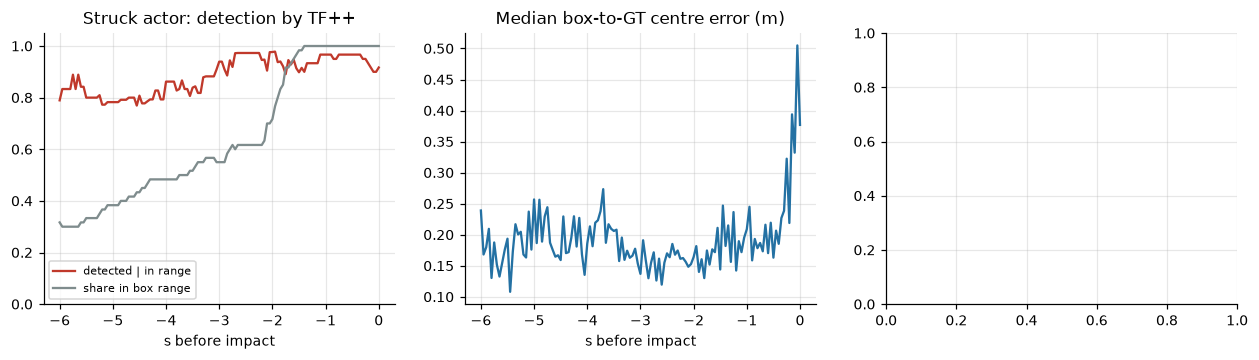

In [9]:
dyn = [e for e in counted if not e["other_type"].startswith("static")]
def track(e):
    return {r["k"]: r for r in data[e["route"]]["events"][e["event"]]["track"]}

def status_at(tr, sec):
    k = -int(round(sec * ew.HZ))
    rs = [tr[j] for j in range(k - 2, k + 3) if j in tr and "x" in tr[j]]
    if not rs:
        return "actor not logged (>60 m or not spawned)"
    if not any(r["in_range"] for r in rs):
        return "out of box range (>32 m)"
    return "detected" if any(r["detected"] for r in rs) else "missed"

rows = []
for sec in (3, 2, 1, 0.5):
    c = collections.Counter(status_at(track(e), sec) for e in dyn)
    inr = c["detected"] + c["missed"]
    rows.append({"time before impact": f"{sec} s", "detected": c["detected"], "missed": c["missed"],
                 "out of box range (>32 m)": c["out of box range (>32 m)"],
                 "not logged": c["actor not logged (>60 m or not spawned)"],
                 "detection rate when in range": c["detected"] / inr if inr else float("nan")})
print(f"collisions with a vehicle or pedestrian: {len(dyn)}")
show_table(rows, list(rows[0]), fmt={"detection rate when in range": pct})
write_csv("detection_at_horizons", rows, list(rows[0]))

ks = np.arange(-120, 1)
det_rate, inr_rate, err_med = [], [], []
for k in ks:
    st = [track(e).get(k) for e in dyn]
    inr = [s for s in st if s and "x" in s and s["in_range"]]
    det_rate.append(np.mean([s["detected"] for s in inr]) if inr else np.nan)
    inr_rate.append(len(inr) / len(dyn))
    errs = [s["det_err"] for s in inr if s["detected"]]
    err_med.append(np.median(errs) if errs else np.nan)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].plot(ks * ew.DT, det_rate, color="#c0392b", label="detected | in range")
axes[0].plot(ks * ew.DT, inr_rate, color="#7f8c8d", label="share in box range")
axes[0].set_ylim(0, 1.05); axes[0].legend(fontsize=7); axes[0].set_xlabel("s before impact"); axes[0].set_title("Struck actor: detection by TF++")
axes[1].plot(ks * ew.DT, err_med, color="#2471a3"); axes[1].set_xlabel("s before impact"); axes[1].set_title("Median box-to-GT centre error (m)")

In [10]:
# dropouts: detected -> not detected -> detected while in range, within the 3 s before impact
drop_rows = []
for e in dyn:
    tr = track(e)
    seq = [tr[k] for k in range(-60, 1) if k in tr and "x" in tr[k] and tr[k]["in_range"]]
    det = np.array([s["detected"] for s in seq], bool)
    if len(det) < 5:
        continue
    gaps, longest, run, seen = 0, 0, 0, False
    for i, v in enumerate(det):
        if v:
            if seen and run > 0:
                gaps += 1
                longest = max(longest, run)
            seen, run = True, 0
        elif seen:
            run += 1
    first = next((k for k in range(-120, 1) if k in tr and tr[k].get("detected")), None)
    drop_rows.append({"route": e["route"], "scenario": e["scenario"], "other": e["other_type"], "situation": e["situation"],
                      "in-range steps (last 3 s)": len(det), "detected share": float(det.mean()),
                      "dropouts": gaps, "longest dropout (s)": longest * ew.DT,
                      "first detected (s before)": -first * ew.DT if first is not None else float("nan")})
dr = np.array([r["dropouts"] for r in drop_rows])
print(f"events with >=5 in-range steps in the last 3 s: {len(drop_rows)}")
print(f"  with at least one dropout: {(dr > 0).sum()}  (median dropouts among them: {np.median(dr[dr > 0]) if (dr > 0).any() else 0})")
print(f"  median first detection: {np.nanmedian([r['first detected (s before)'] for r in drop_rows]):.2f} s before impact")
axes[2].hist(dr, bins=np.arange(0, dr.max() + 2) - 0.5, color="#b9770e")
axes[2].set_xlabel("dropouts in last 3 s (box disappears then reappears)"); axes[2].set_title("Box flicker on the struck actor")
plt.tight_layout(); savefig("03_detection_of_struck_actor"); plt.show()

weak = [r for r in drop_rows if r["detected share"] < 0.8 or r["dropouts"] > 0]
print("events with weak or flickering detection:")
show_table(sorted(weak, key=lambda r: r["detected share"]), list(drop_rows[0]),
           fmt={"detected share": pct, "longest dropout (s)": lambda v: f"{v:.2f}", "first detected (s before)": lambda v: f"{v:.2f}"})
write_csv("detection_dropouts", drop_rows, list(drop_rows[0]))

events with >=5 in-range steps in the last 3 s: 60
  with at least one dropout: 5  (median dropouts among them: 1.0)
  median first detection: 3.40 s before impact


<Figure size 704x528 with 0 Axes>

events with weak or flickering detection:


| route | scenario | other | situation | in-range steps (last 3 s) | detected share | dropouts | longest dropout (s) | first detected (s before) |
|---|---|---|---|---|---|---|---|---|
| 24211 | DynamicObjectCrossing | walker.pedestrian.0011 | pedestrian / cyclist | 39 | 5% | 1 | 0.85 | 0.90 |
| 24224 | DynamicObjectCrossing | walker.pedestrian.0011 | pedestrian / cyclist | 46 | 26% | 0 | 0.00 | 0.75 |
| 24206 | ParkingCrossingPedestrian | walker.pedestrian.0039 | pedestrian / cyclist | 39 | 51% | 0 | 0.00 | 1.10 |
| 3731 | VehicleTurningRoutePedestrian | walker.pedestrian.0011 | pedestrian / cyclist | 61 | 61% | 4 | 0.90 | 4.20 |
| 1852 | AccidentTwoWays | vehicle.dodge.charger_police_2020 | obstacle bypass | 61 | 64% | 0 | 0.00 | 2.05 |
| 26950 | OppositeVehicleRunningRedLight | vehicle.dodge.charger_police_2020 | junction turn / crossing | 32 | 72% | 0 | 0.00 | 1.10 |
| 23687 | HighwayExit | vehicle.mercedes.coupe_2020 | junction turn / crossing | 61 | 92% | 2 | 0.20 | 3.45 |
| 25358 | StaticCutIn | vehicle.ford.crown | struck while stopped / from behind | 61 | 93% | 1 | 0.20 | 6.00 |
| 25424 | ConstructionObstacleTwoWays | vehicle.chevrolet.impala | obstacle bypass | 31 | 94% | 1 | 0.05 | 1.45 |

**Context: how well TF++ detects all nearby actors.** This uses every ground-truth vehicle or pedestrian within box range, sampled every 10th step across all routes.

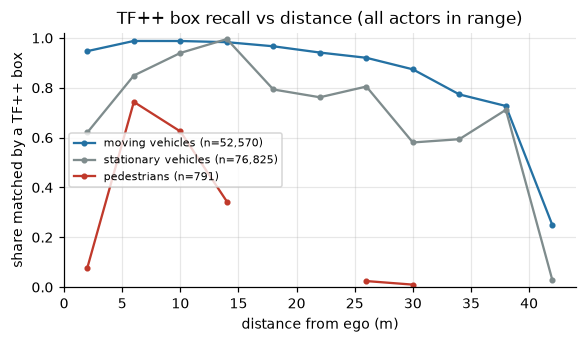

overall recall within range: vehicles 84.9%, pedestrians 29.5%


In [11]:
S = np.concatenate([d["det_sample"] for d in data.values()])
dist, walker, det, spd = S[:, 0], S[:, 1] > 0.5, S[:, 2] > 0.5, S[:, 3]
bins = np.arange(0, 46, 4)
fig, ax = plt.subplots(figsize=(6, 3))
for mask, lab, c in ((~walker & (spd > 0.5), "moving vehicles", "#2471a3"), (~walker & (spd <= 0.5), "stationary vehicles", "#7f8c8d"),
                     (walker, "pedestrians", "#c0392b")):
    idx = np.digitize(dist[mask], bins)
    r = [det[mask][idx == i].mean() if (idx == i).sum() > 30 else np.nan for i in range(1, len(bins))]
    ax.plot(bins[:-1] + 2, r, marker="o", ms=3, color=c, label=f"{lab} (n={mask.sum():,})")
ax.set_xlabel("distance from ego (m)"); ax.set_ylabel("share matched by a TF++ box"); ax.set_ylim(0, 1.02); ax.legend(fontsize=7)
ax.set_title("TF++ box recall vs distance (all actors in range)")
savefig("03b_box_recall_vs_distance"); plt.show()
print(f"overall recall within range: vehicles {det[~walker].mean():.1%}, pedestrians {det[walker].mean():.1%}")

**TF++'s box speed and heading outputs cannot be used directly.** For matched vehicle boxes, the table compares TF++'s own box `speed` field and box heading with ground truth, and with the velocity and heading this analysis estimates by **tracking TF++'s boxes from frame to frame**.

Tracking runs in TF++'s own odometry frame (`ego_position`, `ego_yaw`), so it stays TF++-observable:

- **Association:** greedy nearest neighbour within 2.5 m.
- **Velocity:** box-centre displacement over the last 0.5 s.
- **Heading:** taken from the motion direction once the tracked speed is above 1 m/s.

All "observable" geometry in this notebook uses the tracked velocity.

In [12]:
gt_spd, raw_spd, trk_spd, yaw_raw, yaw_trk = S[:, 3], S[:, 4], S[:, 5], S[:, 6], S[:, 7]
rows = []
for lo, hi in ((0, 0.5), (0.5, 3), (3, 8), (8, 30)):
    m = det & ~walker & (gt_spd >= lo) & (gt_spd < hi)
    rows.append({"GT speed (m/s)": f"{lo}-{hi}", "matched boxes": int(m.sum()),
                 "TF++ box speed, median": float(np.nanmedian(raw_spd[m])), "tracked speed, median": float(np.nanmedian(trk_spd[m])),
                 "abs error: TF++ box speed": float(np.nanmean(np.abs(raw_spd[m] - gt_spd[m]))),
                 "abs error: tracked": float(np.nanmean(np.abs(trk_spd[m] - gt_spd[m]))),
                 "heading off >90 deg: TF++ box": float(np.nanmean(yaw_raw[m] > 90)), "heading off >90 deg: tracked": float(np.nanmean(yaw_trk[m] > 90))})
show_table(rows, list(rows[0]), fmt={k: (lambda v: f"{v:.2f}") for k in list(rows[0])[2:6]} | {k: pct for k in list(rows[0])[6:]})
write_csv("box_speed_heading_check", rows, list(rows[0]))

| GT speed (m/s) | matched boxes | TF++ box speed, median | tracked speed, median | abs error: TF++ box speed | abs error: tracked | heading off >90 deg: TF++ box | heading off >90 deg: tracked |
|---|---|---|---|---|---|---|---|
| 0-0.5 | 61066 | 0.00 | 0.00 | 0.01 | 0.36 | 3% | 8% |
| 0.5-3 | 7208 | 0.00 | 1.37 | 1.77 | 1.00 | 2% | 3% |
| 3-8 | 16728 | 0.00 | 5.51 | 5.92 | 1.30 | 5% | 1% |
| 8-30 | 24889 | 0.00 | 8.32 | 9.33 | 0.95 | 11% | 0% |

## 4. Geometric analysis: TF++'s planned path against actors' predicted motion

**Ego motion.** The ego follows **TF++'s own predicted path**. The path is distance-sampled, so it is given timing by a speed profile: start at the current speed, then move toward TF++'s target speed at +2 / −4 m/s². Beyond the last path point (about 11 m ahead) it is extended straight.

**Actor motion.** Other actors keep their current position, heading and speed (constant velocity). Ego and actors are both modelled as three discs covering the box. Two motion sources are compared:

- the struck actor's **ground-truth** state (offline), and
- the **TF++ box matched to it** (observable), using the tracked box velocity from Section 3, because TF++'s own box speed output is always 0.

**Measures** over a 3 s horizon:

- **TTC:** the first time the two boxes overlap.
- **Minimum clearance:** the smallest gap, in metres.
- **Spatial conflict:** the two swept paths overlap at *any* pair of times.
- **Time gap:** the smallest difference between when the ego and the actor reach the overlap. This is what decides whether crossing paths are actually dangerous.

A constant-turn-rate (CTRV) ego rollout, which ignores TF++'s plan, is shown for comparison.

| motion model | TTC threshold | flagged at all | >= 1 s before impact | >= 2 s before impact | median onset (s) |
|---|---|---|---|---|---|
| GT actor, CTRV ego (ignores TF++ plan) | < 3.0 s | 98% | 28% | 7% | 0.60 |
| GT actor, CTRV ego (ignores TF++ plan) | < 1.5 s | 98% | 27% | 5% | 0.58 |
| GT actor, TF++ planned path | < 3.0 s | 95% | 58% | 22% | 1.12 |
| GT actor, TF++ planned path | < 1.5 s | 95% | 52% | 5% | 1.02 |
| TF++ box, TF++ planned path (observable) | < 3.0 s | 87% | 52% | 12% | 1.00 |
| TF++ box, TF++ planned path (observable) | < 1.5 s | 87% | 42% | 3% | 0.90 |

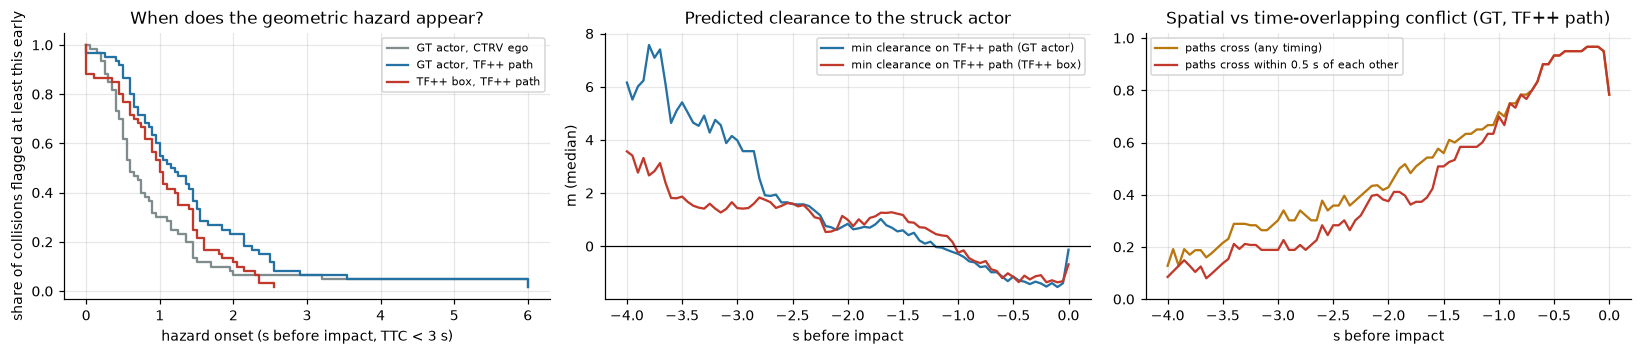

| time before impact | actors logged | paths cross (spatial) | cross within 0.5 s (temporal overlap) | TTC < 3 s on TF++ path | median clearance (m) |
|---|---|---|---|---|---|
| 3 s | 53 | 30% | 19% | 17% | 3.98 |
| 2 s | 56 | 43% | 38% | 32% | 0.84 |
| 1 s | 60 | 72% | 70% | 62% | -0.29 |

In [13]:
def hazard_onset(tr, key, thr):
    ks = sorted(k for k, r in tr.items() if r.get(key, np.inf) < thr)
    if not ks or ks[-1] < -5:
        return 0.0
    start = ks[-1]
    for k in ks[::-1][1:]:
        if start - k <= 5:
            start = k
        else:
            break
    return -start * ew.DT

rows, onsets = [], {}
for key, lab in (("gt_ttc_ctrv", "GT actor, CTRV ego (ignores TF++ plan)"), ("gt_ttc_plan", "GT actor, TF++ planned path"),
                 ("pred_ttc_plan", "TF++ box, TF++ planned path (observable)")):
    for thr in (3.0, 1.5):
        o = np.array([hazard_onset(track(e), key, thr) for e in dyn])
        onsets[(key, thr)] = o
        rows.append({"motion model": lab, "TTC threshold": f"< {thr} s", "flagged at all": (o > 0).mean(),
                     ">= 1 s before impact": (o >= 1).mean(), ">= 2 s before impact": (o >= 2).mean(),
                     "median onset (s)": float(np.median(o))})
show_table(rows, list(rows[0]), fmt={k: pct for k in ["flagged at all", ">= 1 s before impact", ">= 2 s before impact"]} | {"median onset (s)": lambda v: f"{v:.2f}"})
write_csv("geometric_hazard_onset", rows, list(rows[0]))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
for (key, lab), c in zip((("gt_ttc_ctrv", "GT actor, CTRV ego"), ("gt_ttc_plan", "GT actor, TF++ path"),
                          ("pred_ttc_plan", "TF++ box, TF++ path")), ("#7f8c8d", "#2471a3", "#c0392b")):
    o = np.sort(onsets[(key, 3.0)])
    axes[0].step(o, 1 - np.arange(len(o)) / len(o), where="post", color=c, label=lab)
axes[0].set_xlabel("hazard onset (s before impact, TTC < 3 s)"); axes[0].set_ylabel("share of collisions flagged at least this early")
axes[0].legend(fontsize=7); axes[0].set_title("When does the geometric hazard appear?")

ks = np.arange(-80, 1)
for key, lab, c in (("gt_clear_plan", "min clearance on TF++ path (GT actor)", "#2471a3"),
                    ("pred_clear_plan", "min clearance on TF++ path (TF++ box)", "#c0392b")):
    med = [np.nanmedian([track(e)[k].get(key, np.nan) for e in dyn if k in track(e)]) for k in ks]
    axes[1].plot(ks * ew.DT, med, color=c, label=lab)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xlabel("s before impact"); axes[1].set_ylabel("m (median)")
axes[1].legend(fontsize=7); axes[1].set_title("Predicted clearance to the struck actor")

conf_rate, gap_med, same_time = [], [], []
for k in ks:
    rs = [track(e).get(k) for e in dyn]
    rs = [r for r in rs if r and "gt_conflict" in r]
    c = [r for r in rs if r["gt_conflict"]]
    conf_rate.append(len(c) / len(rs) if rs else np.nan)
    same_time.append(np.mean([r["gt_pet"] <= 0.5 for r in rs]) if rs else np.nan)
axes[2].plot(ks * ew.DT, conf_rate, color="#b9770e", label="paths cross (any timing)")
axes[2].plot(ks * ew.DT, same_time, color="#c0392b", label="paths cross within 0.5 s of each other")
axes[2].set_ylim(0, 1.02); axes[2].set_xlabel("s before impact"); axes[2].legend(fontsize=7)
axes[2].set_title("Spatial vs time-overlapping conflict (GT, TF++ path)")
plt.tight_layout(); savefig("04_geometric_analysis"); plt.show()

rows = []
for sec in (3, 2, 1):
    k = -int(sec * ew.HZ)
    rs = [track(e).get(k) for e in dyn]
    rs = [r for r in rs if r and "gt_conflict" in r]
    rows.append({"time before impact": f"{sec} s", "actors logged": len(rs),
                 "paths cross (spatial)": np.mean([r["gt_conflict"] for r in rs]),
                 "cross within 0.5 s (temporal overlap)": np.mean([r["gt_pet"] <= 0.5 for r in rs]),
                 "TTC < 3 s on TF++ path": np.mean([r["gt_ttc_plan"] < 3 for r in rs]),
                 "median clearance (m)": float(np.median([r["gt_clear_plan"] for r in rs]))})
show_table(rows, list(rows[0]), fmt={k: pct for k in list(rows[0])[2:5]} | {"median clearance (m)": lambda v: f"{v:.2f}"})

## 5. Safe vs failure: which signals separate crashes from legitimate manoeuvres?

Every window is 2 s long and summarised by the signal's mean over that window.

- **Crash windows:** from 3 s to 1 s before impact. This is the part a monitor could still act on.
- **Safe windows:** the 2 s ending at the peak of a successful manoeuvre.

The table gives the AUROC for telling crash windows from each kind of safe window. 0.5 is chance; above 0.5 means the signal is higher before crashes. Brackets are 95% bootstrap intervals over windows.

The last three columns are matched comparisons: crashes in a situation against successful manoeuvres of the same kind.

In [14]:
from sklearn.metrics import roc_auc_score
SAFE_KEYS = [("ego_speed", "ego speed"), ("target_speed", "target speed"), ("speed_entropy", "speed entropy"),
             ("speed_margin", "speed top-class margin"), ("path_disagree_mean_1s", "path disagreement 1 s"),
             ("path_end_lat_std_1s", "path end-point jitter 1 s"), ("speed_js_mean_1s", "target-speed JS 1 s"),
             ("steer_tv_1s", "steering variation 1 s"), ("pedal_switches_1s", "pedal switches 1 s"), ("brake", "brake"),
             ("risk_plan", "geometric risk, TF++ path + boxes"), ("clear_plan", "min clearance, TF++ path + boxes"),
             ("risk_ctrv", "geometric risk, CTRV + boxes"), ("gt_risk_plan", "offline: GT risk on TF++ path")]

def wstat(items, key, end_off, w=40):
    out = []
    for it in items:
        end = it["step"] + end_off
        if end - w < 0:
            continue
        out.append(feats[it["route"]][key][end - w:end].mean())
    return np.array(out)

def auc_ci(a, b, B=500, seed=0):
    if len(a) < 3 or len(b) < 3:
        return np.nan, (np.nan, np.nan)
    y = np.r_[np.ones(len(a)), np.zeros(len(b))]
    s = np.r_[a, b]
    rng = np.random.default_rng(seed)
    bs = []
    for _ in range(B):
        ia, ib = rng.integers(0, len(a), len(a)), rng.integers(0, len(b), len(b))
        bs.append(roc_auc_score(np.r_[np.ones(len(a)), np.zeros(len(b))], np.r_[a[ia], b[ib]]))
    return roc_auc_score(y, s), tuple(np.percentile(bs, [2.5, 97.5]))

comparisons = [("all crashes", crash, "junction turn"), ("all crashes", crash, "lane change"),
               ("all crashes", crash, "obstacle bypass"), ("all crashes", crash, "normal driving"),
               ("junction crashes", [e for e in crash if e["situation"] == "junction turn / crossing"], "junction turn"),
               ("lane-change / merge crashes", [e for e in crash if e["situation"] in ("lane change", "merge / exit")], "lane change"),
               ("bypass crashes", [e for e in crash if e["situation"] == "obstacle bypass"], "obstacle bypass")]
rows = []
for key, lab in SAFE_KEYS:
    r = {"signal": lab}
    for cname, citems, sname in comparisons:
        a = wstat(citems, key, -20)
        b = wstat(groups[sname], key, 0)
        auc, (lo, hi) = auc_ci(a, b)
        r[f"{cname} vs {sname}"] = f"{auc:.2f} [{lo:.2f}, {hi:.2f}]"
    rows.append(r)
print("n:", {f"{c} vs {s}": (len(ci_), len(groups[s])) for c, ci_, s in comparisons})
show_table(rows, list(rows[0]))
write_csv("safe_vs_failure_auroc", rows, list(rows[0]))

n: {'all crashes vs junction turn': (61, 54), 'all crashes vs lane change': (61, 7), 'all crashes vs obstacle bypass': (61, 28), 'all crashes vs normal driving': (61, 538), 'junction crashes vs junction turn': (17, 54), 'lane-change / merge crashes vs lane change': (8, 7), 'bypass crashes vs obstacle bypass': (16, 28)}


| signal | all crashes vs junction turn | all crashes vs lane change | all crashes vs obstacle bypass | all crashes vs normal driving | junction crashes vs junction turn | lane-change / merge crashes vs lane change | bypass crashes vs obstacle bypass |
|---|---|---|---|---|---|---|---|
| ego speed | 0.57 [0.46, 0.68] | 0.23 [0.12, 0.39] | 0.57 [0.46, 0.68] | 0.38 [0.30, 0.48] | 0.30 [0.12, 0.49] | 0.21 [0.00, 0.45] | 0.77 [0.58, 0.89] |
| target speed | 0.67 [0.58, 0.76] | 0.33 [0.14, 0.55] | 0.64 [0.52, 0.74] | 0.55 [0.46, 0.65] | 0.55 [0.34, 0.72] | 0.57 [0.28, 0.88] | 0.81 [0.67, 0.92] |
| speed entropy | 0.29 [0.20, 0.39] | 0.49 [0.32, 0.67] | 0.43 [0.30, 0.56] | 0.35 [0.27, 0.42] | 0.41 [0.23, 0.58] | 0.36 [0.08, 0.66] | 0.39 [0.24, 0.55] |
| speed top-class margin | 0.75 [0.66, 0.84] | 0.49 [0.33, 0.64] | 0.58 [0.44, 0.70] | 0.69 [0.62, 0.76] | 0.67 [0.51, 0.81] | 0.55 [0.25, 0.88] | 0.63 [0.46, 0.78] |
| path disagreement 1 s | 0.55 [0.45, 0.66] | 0.39 [0.24, 0.55] | 0.43 [0.33, 0.55] | 0.64 [0.58, 0.70] | 0.28 [0.12, 0.46] | 0.54 [0.23, 0.82] | 0.51 [0.30, 0.73] |
| path end-point jitter 1 s | 0.22 [0.13, 0.31] | 0.29 [0.13, 0.44] | 0.33 [0.23, 0.44] | 0.56 [0.50, 0.63] | 0.04 [0.00, 0.09] | 0.32 [0.07, 0.64] | 0.41 [0.19, 0.66] |
| target-speed JS 1 s | 0.63 [0.54, 0.73] | 0.35 [0.16, 0.56] | 0.38 [0.26, 0.51] | 0.65 [0.57, 0.72] | 0.64 [0.47, 0.78] | 0.43 [0.16, 0.70] | 0.49 [0.31, 0.67] |
| steering variation 1 s | 0.45 [0.35, 0.56] | 0.34 [0.19, 0.50] | 0.43 [0.31, 0.54] | 0.53 [0.46, 0.60] | 0.15 [0.02, 0.32] | 0.30 [0.05, 0.61] | 0.62 [0.44, 0.82] |
| pedal switches 1 s | 0.45 [0.35, 0.54] | 0.37 [0.19, 0.57] | 0.28 [0.17, 0.40] | 0.30 [0.24, 0.38] | 0.46 [0.30, 0.64] | 0.38 [0.12, 0.65] | 0.32 [0.17, 0.51] |
| brake | 0.69 [0.60, 0.79] | 0.64 [0.48, 0.80] | 0.37 [0.24, 0.49] | 0.44 [0.35, 0.53] | 0.71 [0.53, 0.86] | 0.29 [0.04, 0.57] | 0.33 [0.16, 0.51] |
| geometric risk, TF++ path + boxes | 0.71 [0.61, 0.81] | 0.59 [0.35, 0.81] | 0.47 [0.35, 0.59] | 0.67 [0.59, 0.74] | 0.80 [0.65, 0.92] | 0.64 [0.34, 0.91] | 0.55 [0.38, 0.73] |
| min clearance, TF++ path + boxes | 0.25 [0.17, 0.35] | 0.37 [0.14, 0.64] | 0.62 [0.51, 0.73] | 0.43 [0.35, 0.50] | 0.28 [0.11, 0.48] | 0.25 [0.04, 0.54] | 0.52 [0.34, 0.67] |
| geometric risk, CTRV + boxes | 0.53 [0.43, 0.63] | 0.58 [0.37, 0.78] | 0.38 [0.27, 0.50] | 0.55 [0.47, 0.62] | 0.54 [0.37, 0.72] | 0.43 [0.15, 0.70] | 0.54 [0.37, 0.72] |
| offline: GT risk on TF++ path | 0.72 [0.63, 0.81] | 0.56 [0.36, 0.76] | 0.47 [0.36, 0.59] | 0.73 [0.67, 0.79] | 0.78 [0.65, 0.88] | 0.48 [0.18, 0.77] | 0.59 [0.42, 0.78] |

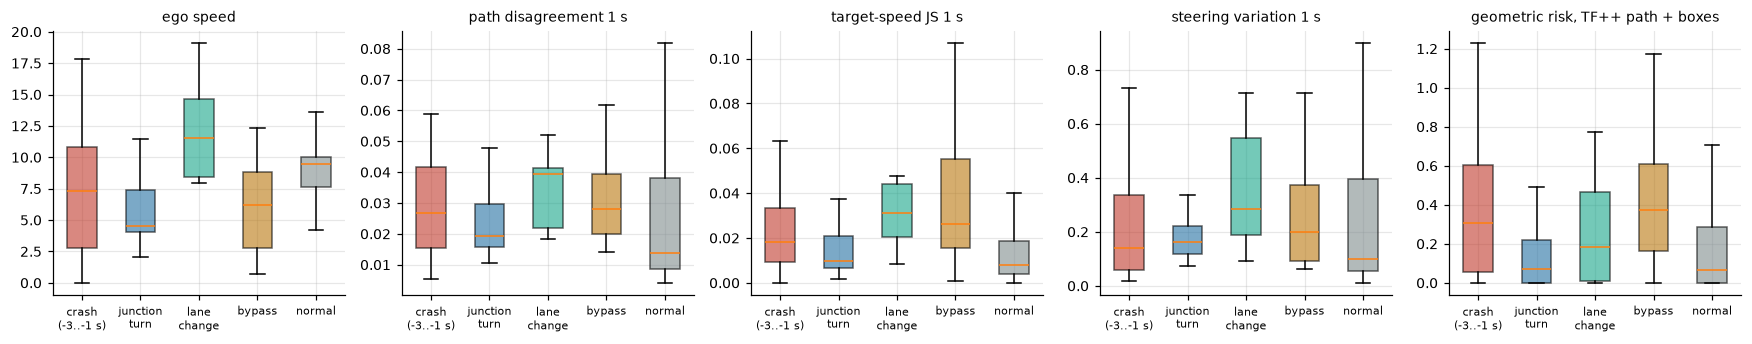

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, key in zip(axes, ["ego_speed", "path_disagree_mean_1s", "speed_js_mean_1s", "steer_tv_1s", "risk_plan"]):
    data_ = [wstat(crash, key, -20)] + [wstat(groups[s], key, 0) for s in ("junction turn", "lane change", "obstacle bypass", "normal driving")]
    bp = ax.boxplot(data_, showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], [COL[k] for k in ("crash", "junction turn", "lane change", "obstacle bypass", "normal driving")]):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    ax.set_xticks(range(1, 6), ["crash\n(-3..-1 s)", "junction\nturn", "lane\nchange", "bypass", "normal"], fontsize=7)
    ax.set_title(dict(SAFE_KEYS)[key], fontsize=9)
plt.tight_layout(); savefig("05_safe_vs_failure"); plt.show()

## 6–7. Baselines and early-warning evaluation

**Dataset.** One row per 20 Hz step. A step's label is 1 if a counted collision follows within 3 s. Excluded steps:

- the first 2 s of each route;
- the 3 s after any contact (post-crash dynamics);
- the 3 s before uncounted contacts or before collisions without a clean history (ambiguous labels);
- whole routes whose only failure is off-route, because that failure has no timestamp.

**Leakage control.**

- *Outer split:* 5-fold cross-validation **grouped by route**. A route's overlapping windows never appear in both train and test.
- *Thresholds:* each alarm threshold is chosen **only on validation data**. Within every outer training fold, a 4-fold route-grouped inner split produces out-of-fold validation scores, and the threshold is the lowest one that keeps debounced false alarms at or below the target (1 or 3 per minute). The model is then refit on the whole training fold and applied, with that threshold, to the untouched test routes.

**Alarms.**

- Consecutive alarm steps, with gaps up to 1 s, form one alarm episode.
- A **false alarm** is an episode that starts outside the 3 s before a collision. It counts **once per started 5 s** of alarm during normal driving, so an alarm that stays on (which would stop the car) is not cheaper than several short ones; an always-on alarm costs 12 per minute. False alarms per minute are measured over normal (label 0) driving.
- An event is **recalled ≥ X s** if an alarm is active at some step between 3 s and X s before impact.
- **Lead time** is the earliest alarm in that 3 s window.

**Overlapping windows.** Event-level recall counts each collision once. All confidence intervals come from resampling **routes** with replacement (300 resamples), not steps.

**Models.** Rules are a single feature with a validated threshold, its direction set on training data. "LR" is a standardised, class-balanced logistic regression. The feature groups (exact lists in `ew_analysis.py`):

| Group | Features | Observable? |
|---|---|---|
| Speed | ego speed | yes |
| TF++ confidence | ego speed, target speed, entropy, top-class margin, top probability | yes |
| Temporal instability (proposal §2.2) | Path evolution: path disagreement (1 s / 2 s mean, 1 s max), end-point jitter, curvature change. Speed distribution: JS divergence (1 s, 2 s), entropy change. Controls: steering variation and reversals, pedal switches, jerk. Execution context: target-speed tracking gap, route-target alignment | yes |
| Current-frame geometry | Risk on TF++ path and on CTRV (TTC against TF++ boxes), minimum clearance, time gap, conflict flag, nearest box in corridor, closing speed, box count, TF++'s own `bb_in_front` flag | yes |
| Current frame | Geometry + confidence + path curvature and lateral offset | yes |
| Current frame + temporal | Current frame + temporal instability + geometric trend (1 s max risk, 1 s clearance change) | yes |
| GT geometry (offline reference) | Same geometric risk, but with ground-truth actors | **no**: an upper reference only |

In [16]:
t0 = time.time()
F, M, ev_index, untimed = ew.build_dataset(routes, ckpts, data, events)
EIDS = sorted({e["eid"] for e in ev_index})
groups_route = M["route"]
minutes_neg = (M["y"] == 0).sum() * ew.DT / 60
print(f"routes: {len(np.unique(M['route']))} (excluded, off-route only: {untimed})")
print(f"steps: {len(M['y']):,}  positive: {M['y'].sum():,}  moving: {M['moving'].sum():,}  positive moving: {M['y'][M['moving']].sum():,}")
print(f"collision events evaluated: {len(EIDS)}  normal driving: {minutes_neg:.0f} min")

RES, SCORES = {}, {}
for name, (kind, spec) in ew.METHODS.items():
    score, thr, fold = ew.run_method(kind, spec, F, M, ev_index, groups_route)
    ev = ew.evaluate(score, thr, M, EIDS)
    ev["ci"] = ew.bootstrap(score, thr, M, EIDS, B=300, targets=(1.0, 3.0))
    RES[name], SCORES[name] = ev, (score, thr)
    print(f"{name:45s} AUROC(moving) {ev['auroc_moving']:.3f}  recall>=1s@1/min {ev[1.0]['recall_1s']:.2f}  "
          f"@3/min {ev[3.0]['recall_1s']:.2f}  ({time.time() - t0:.0f} s)")

routes: 214 (excluded, off-route only: ['2790', '23658', '23910', '24098', '25896'])
steps: 147,531  positive: 3,042  moving: 43,506  positive moving: 2,477
collision events evaluated: 60  normal driving: 120 min


Rule: speed                                   AUROC(moving) 0.626  recall>=1s@1/min 0.33  @3/min 0.53  (8 s)


Rule: TF++ entropy                            AUROC(moving) 0.388  recall>=1s@1/min 0.12  @3/min 0.38  (16 s)


Rule: path disagreement 1 s                   AUROC(moving) 0.673  recall>=1s@1/min 0.12  @3/min 0.30  (22 s)


Rule: speed-distribution JS 1 s               AUROC(moving) 0.631  recall>=1s@1/min 0.17  @3/min 0.68  (29 s)


Rule: steering variation 1 s                  AUROC(moving) 0.660  recall>=1s@1/min 0.23  @3/min 0.37  (36 s)


... (4 outputs left out)

LR: current-frame geometry                    AUROC(moving) 0.716  recall>=1s@1/min 0.35  @3/min 0.55  (77 s)


LR: current frame (geometry + confidence)     AUROC(moving) 0.772  recall>=1s@1/min 0.40  @3/min 0.68  (89 s)


LR: current frame + temporal                  AUROC(moving) 0.772  recall>=1s@1/min 0.30  @3/min 0.70  (106 s)


Offline ref: GT geometry on TF++ path         AUROC(moving) 0.754  recall>=1s@1/min 0.30  @3/min 0.72  (114 s)


In [17]:
rows = []
for name, ev in RES.items():
    c = ev["ci"]
    r = {"method": name,
         "AUROC all": f"{ev['auroc']:.3f}",
         "AUROC moving": f"{ev['auroc_moving']:.3f} [{c['auroc_moving'][0]:.3f}, {c['auroc_moving'][1]:.3f}]",
         "AUPRC moving": f"{ev['auprc_moving']:.3f} [{c['auprc_moving'][0]:.3f}, {c['auprc_moving'][1]:.3f}]"}
    for t in (1.0, 3.0):
        a = ev[t]
        lv = np.array(list(a["lead"].values()))
        r[f"FA/min (target {t:g})"] = f"{a['fa_per_min']:.2f} [{c[f'fa_per_min@{t}'][0]:.2f}, {c[f'fa_per_min@{t}'][1]:.2f}]"
        r[f"recall >=1 s @{t:g}"] = f"{a['recall_1s']:.0%} {ci(c[f'recall_1s@{t}'])}"
        r[f"recall >=2 s @{t:g}"] = f"{a['recall_2s']:.0%} {ci(c[f'recall_2s@{t}'])}"
        r[f"median lead (s) @{t:g}"] = f"{np.median(lv):.2f}"
        r[f"time in alarm @{t:g}"] = f"{a['alarm_time_frac']:.1%}"
    rows.append(r)
cols1 = ["method", "AUROC all", "AUROC moving", "AUPRC moving"]
cols2 = ["method"] + [k for k in rows[0] if k.endswith("@1") or "target 1)" in k]
cols3 = ["method"] + [k for k in rows[0] if k.endswith("@3") or "target 3)" in k]
display(Markdown("**Ranking quality** (out-of-fold, 95% route-bootstrap CI). Moving = ego speed > 2 m/s; base rate " +
                 f"{M['y'][M['moving']].mean():.1%} of moving steps."))
show_table(rows, cols1)
display(Markdown("**Alarm at a validated threshold: target 1 false alarm per minute.** The false-alarm rate is what was measured on the test routes."))
show_table(rows, cols2)
display(Markdown("**Alarm at a validated threshold: target 3 false alarms per minute.**"))
show_table(rows, cols3)
write_csv("baseline_results", rows, list(rows[0]))

**Ranking quality** (out-of-fold, 95% route-bootstrap CI). Moving = ego speed > 2 m/s; base rate 5.7% of moving steps.

| method | AUROC all | AUROC moving | AUPRC moving |
|---|---|---|---|
| Rule: speed | 0.815 | 0.626 [0.562, 0.687] | 0.099 [0.069, 0.145] |
| Rule: TF++ entropy | 0.646 | 0.388 [0.338, 0.435] | 0.057 [0.040, 0.075] |
| Rule: path disagreement 1 s | 0.623 | 0.673 [0.613, 0.729] | 0.101 [0.069, 0.151] |
| Rule: speed-distribution JS 1 s | 0.808 | 0.631 [0.560, 0.687] | 0.095 [0.062, 0.140] |
| Rule: steering variation 1 s | 0.627 | 0.660 [0.604, 0.709] | 0.109 [0.072, 0.162] |
| Rule: TTC on TF++ path (boxes) | 0.674 | 0.687 [0.650, 0.725] | 0.262 [0.193, 0.334] |
| LR: speed | 0.809 | 0.626 [0.562, 0.687] | 0.099 [0.068, 0.147] |
| LR: TF++ confidence | 0.815 | 0.641 [0.578, 0.704] | 0.104 [0.071, 0.153] |
| LR: temporal instability | 0.853 | 0.730 [0.670, 0.780] | 0.122 [0.081, 0.167] |
| LR: current-frame geometry | 0.834 | 0.716 [0.662, 0.767] | 0.198 [0.139, 0.266] |
| LR: current frame (geometry + confidence) | 0.850 | 0.772 [0.720, 0.816] | 0.258 [0.185, 0.336] |
| LR: current frame + temporal | 0.858 | 0.772 [0.721, 0.819] | 0.235 [0.162, 0.309] |
| Offline ref: GT geometry on TF++ path | 0.840 | 0.754 [0.709, 0.795] | 0.319 [0.250, 0.394] |

**Alarm at a validated threshold: target 1 false alarm per minute.** The false-alarm rate is what was measured on the test routes.

| method | FA/min (target 1) | recall >=1 s @1 | recall >=2 s @1 | median lead (s) @1 | time in alarm @1 |
|---|---|---|---|---|---|
| Rule: speed | 0.99 [0.72, 1.31] | 33% [22%, 45%] | 15% [7%, 25%] | 0.00 | 2.6% |
| Rule: TF++ entropy | 0.87 [0.46, 1.37] | 12% [4%, 20%] | 5% [0%, 12%] | 0.00 | 0.3% |
| Rule: path disagreement 1 s | 1.22 [0.75, 1.80] | 12% [5%, 20%] | 10% [3%, 18%] | 0.00 | 2.8% |
| Rule: speed-distribution JS 1 s | 0.99 [0.72, 1.30] | 17% [7%, 26%] | 8% [2%, 15%] | 0.00 | 1.6% |
| Rule: steering variation 1 s | 0.97 [0.72, 1.24] | 23% [14%, 34%] | 10% [3%, 18%] | 0.12 | 1.9% |
| Rule: TTC on TF++ path (boxes) | 0.95 [0.26, 2.18] | 7% [2%, 13%] | 3% [0%, 8%] | 0.00 | 1.6% |
| LR: speed | 1.00 [0.73, 1.32] | 33% [22%, 45%] | 15% [7%, 25%] | 0.00 | 2.7% |
| LR: TF++ confidence | 0.92 [0.67, 1.24] | 33% [22%, 45%] | 17% [9%, 26%] | 0.00 | 2.3% |
| LR: temporal instability | 0.82 [0.59, 1.07] | 15% [8%, 24%] | 5% [0%, 12%] | 0.00 | 0.8% |
| LR: current-frame geometry | 0.90 [0.68, 1.18] | 35% [25%, 46%] | 12% [4%, 19%] | 0.70 | 0.9% |
| LR: current frame (geometry + confidence) | 0.78 [0.58, 1.00] | 40% [29%, 52%] | 17% [8%, 29%] | 0.80 | 0.5% |
| LR: current frame + temporal | 0.81 [0.57, 1.08] | 30% [19%, 42%] | 8% [2%, 17%] | 0.55 | 0.4% |
| Offline ref: GT geometry on TF++ path | 0.90 [0.67, 1.17] | 30% [20%, 41%] | 10% [3%, 18%] | 0.75 | 0.9% |

**Alarm at a validated threshold: target 3 false alarms per minute.**

| method | FA/min (target 3) | recall >=1 s @3 | recall >=2 s @3 | median lead (s) @3 | time in alarm @3 |
|---|---|---|---|---|---|
| Rule: speed | 2.98 [2.32, 3.70] | 53% [42%, 68%] | 32% [22%, 43%] | 1.18 | 6.2% |
| Rule: TF++ entropy | 3.16 [2.24, 4.34] | 38% [26%, 50%] | 28% [17%, 38%] | 0.00 | 1.8% |
| Rule: path disagreement 1 s | 2.99 [1.92, 4.23] | 30% [19%, 41%] | 18% [10%, 28%] | 0.35 | 12.9% |
| Rule: speed-distribution JS 1 s | 2.99 [2.41, 3.65] | 68% [57%, 79%] | 55% [43%, 66%] | 2.40 | 8.1% |
| Rule: steering variation 1 s | 3.06 [2.14, 4.12] | 37% [26%, 50%] | 18% [10%, 31%] | 0.45 | 7.1% |
| Rule: TTC on TF++ path (boxes) | 2.83 [1.68, 4.13] | 18% [9%, 28%] | 8% [2%, 15%] | 0.70 | 2.3% |
| LR: speed | 3.01 [2.34, 3.73] | 53% [42%, 68%] | 32% [22%, 43%] | 1.18 | 6.2% |
| LR: TF++ confidence | 2.80 [1.95, 3.94] | 55% [44%, 68%] | 37% [26%, 48%] | 1.40 | 6.6% |
| LR: temporal instability | 2.82 [2.24, 3.56] | 58% [45%, 72%] | 37% [26%, 47%] | 1.23 | 5.0% |
| LR: current-frame geometry | 3.16 [2.37, 4.19] | 55% [41%, 68%] | 18% [10%, 30%] | 1.12 | 3.8% |
| LR: current frame (geometry + confidence) | 2.68 [1.99, 3.52] | 68% [56%, 81%] | 32% [21%, 45%] | 1.38 | 3.7% |
| LR: current frame + temporal | 2.65 [2.09, 3.30] | 70% [59%, 81%] | 42% [30%, 54%] | 1.65 | 3.9% |
| Offline ref: GT geometry on TF++ path | 2.96 [2.34, 3.54] | 72% [61%, 82%] | 33% [20%, 45%] | 1.53 | 5.6% |

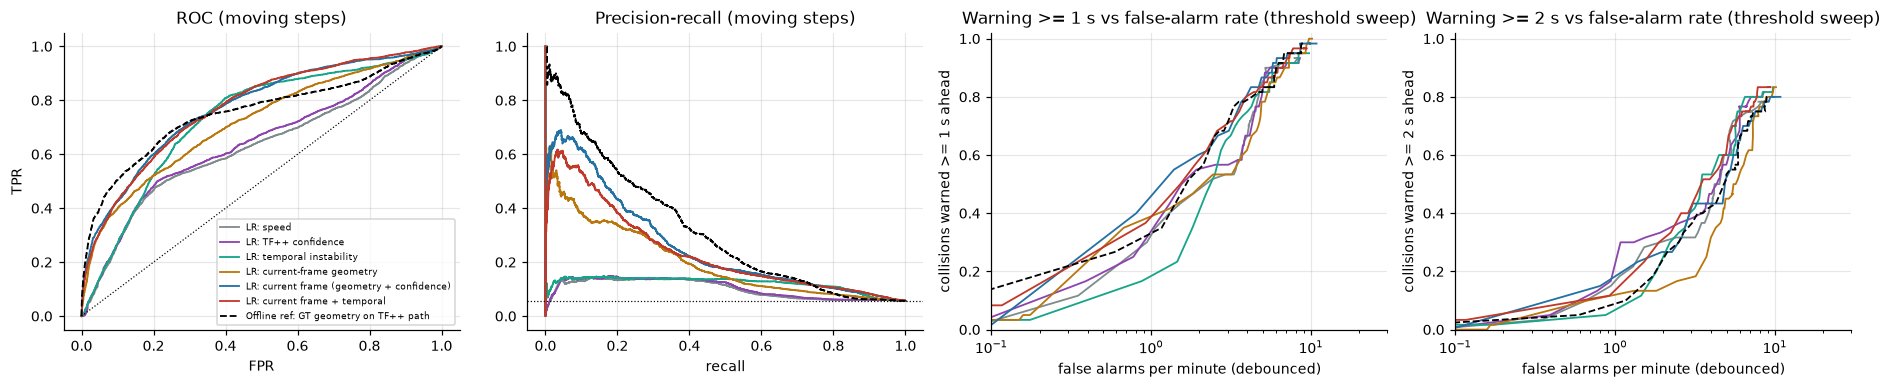

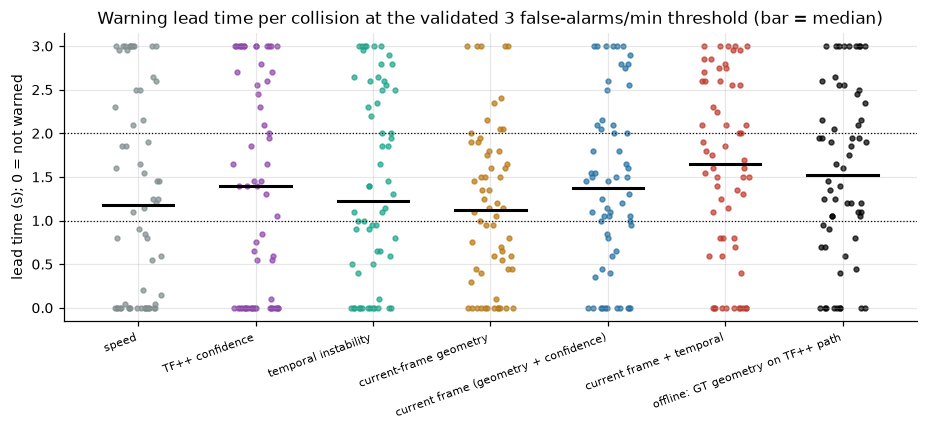

In [18]:
from sklearn.metrics import roc_curve, precision_recall_curve
SHOW = ["LR: speed", "LR: TF++ confidence", "LR: temporal instability", "LR: current-frame geometry",
        "LR: current frame (geometry + confidence)", "LR: current frame + temporal", "Offline ref: GT geometry on TF++ path"]
CS = ["#7f8c8d", "#8e44ad", "#17a589", "#b9770e", "#2471a3", "#c0392b", "#000000"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
mv = M["moving"]
for name, c in zip(SHOW, CS):
    s = SCORES[name][0]
    ls = "--" if name.startswith("Offline") else "-"
    fpr, tpr, _ = roc_curve(M["y"][mv], s[mv]); axes[0].plot(fpr, tpr, color=c, ls=ls, lw=1.2, label=name)
    p, r, _ = precision_recall_curve(M["y"][mv], s[mv]); axes[1].plot(r, p, color=c, ls=ls, lw=1.2)
    curve = ew.recall_fa_curve(s, M, EIDS)
    axes[2].plot(curve[:, 0], curve[:, 1], color=c, ls=ls, lw=1.2)
    axes[3].plot(curve[:, 0], curve[:, 2], color=c, ls=ls, lw=1.2)
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8); axes[0].set_title("ROC (moving steps)"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].legend(fontsize=6)
axes[1].axhline(M["y"][mv].mean(), color="k", ls=":", lw=0.8); axes[1].set_title("Precision-recall (moving steps)"); axes[1].set_xlabel("recall")
for ax, h in ((axes[2], 1), (axes[3], 2)):
    ax.set_xscale("log"); ax.set_xlim(0.1, 30); ax.set_ylim(0, 1.02)
    ax.set_xlabel("false alarms per minute (debounced)"); ax.set_ylabel(f"collisions warned >= {h} s ahead")
    ax.set_title(f"Warning >= {h} s vs false-alarm rate (threshold sweep)")
plt.tight_layout(); savefig("07_roc_pr_recall_vs_fa"); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (name, c) in enumerate(zip(SHOW, CS)):
    lv = np.array(list(RES[name][3.0]["lead"].values()))
    ax.scatter(np.full(len(lv), i) + np.random.default_rng(i).uniform(-0.2, 0.2, len(lv)), lv, s=10, color=c, alpha=0.7)
    ax.plot([i - 0.3, i + 0.3], [np.median(lv)] * 2, color="k", lw=2)
ax.set_xticks(range(len(SHOW)), [s.replace("LR: ", "").replace("Offline ref: ", "offline: ") for s in SHOW], rotation=20, fontsize=7, ha="right")
ax.set_ylabel("lead time (s); 0 = not warned"); ax.axhline(1, color="k", ls=":", lw=0.8); ax.axhline(2, color="k", ls=":", lw=0.8)
ax.set_title("Warning lead time per collision at the validated 3 false-alarms/min threshold (bar = median)")
savefig("07b_lead_time_distribution"); plt.show()

### Does temporal history add value beyond current-frame geometry and TF++ confidence?

This is a paired route-bootstrap of the difference between **current frame + temporal** and **current frame**. Both use the same out-of-fold predictions and validated thresholds. A 95% interval that excludes 0 indicates a real difference.

In [19]:
def paired_diff(a_name, b_name, B=500, seed=1):
    rng = np.random.default_rng(seed)
    sa, ta = SCORES[a_name]; sb, tb = SCORES[b_name]
    routes_u = np.unique(M["route"])
    by_route = {r: np.where(M["route"] == r)[0] for r in routes_u}
    from sklearn.metrics import average_precision_score
    out = collections.defaultdict(list)
    la = {t: RES[a_name][t]["lead"] for t in (1.0, 3.0)}; lb = {t: RES[b_name][t]["lead"] for t in (1.0, 3.0)}
    ev_route = {e: M["route"][np.where(M["eid"] == e)[0][0]] for e in EIDS}
    for _ in range(B):
        samp = rng.choice(routes_u, len(routes_u))
        idx = np.concatenate([by_route[r] for r in samp]); idx = idx[M["moving"][idx]]
        out["AUPRC moving"].append(average_precision_score(M["y"][idx], sa[idx]) - average_precision_score(M["y"][idx], sb[idx]))
        cnt = collections.Counter(samp)
        evs = [e for e in EIDS for _ in range(cnt.get(ev_route[e], 0))]
        for t in (1.0, 3.0):
            out[f"recall >=1 s @{t:g}/min"].append(np.mean([la[t][e] >= 1 for e in evs]) - np.mean([lb[t][e] >= 1 for e in evs]))
            out[f"recall >=2 s @{t:g}/min"].append(np.mean([la[t][e] >= 2 for e in evs]) - np.mean([lb[t][e] >= 2 for e in evs]))
    point = {"AUPRC moving": RES[a_name]["auprc_moving"] - RES[b_name]["auprc_moving"]}
    for t in (1.0, 3.0):
        point[f"recall >=1 s @{t:g}/min"] = RES[a_name][t]["recall_1s"] - RES[b_name][t]["recall_1s"]
        point[f"recall >=2 s @{t:g}/min"] = RES[a_name][t]["recall_2s"] - RES[b_name][t]["recall_2s"]
    return [{"comparison": f"{a_name.replace('LR: ', '')} minus {b_name.replace('LR: ', '')}", "metric": k,
             "difference": point[k], "95% CI": f"[{np.percentile(v, 2.5):+.3f}, {np.percentile(v, 97.5):+.3f}]"} for k, v in out.items()]

rows = (paired_diff("LR: current frame + temporal", "LR: current frame (geometry + confidence)")
        + paired_diff("LR: temporal instability", "LR: TF++ confidence")
        + paired_diff("LR: temporal instability", "LR: current-frame geometry")
        + paired_diff("LR: temporal instability", "LR: speed"))
show_table(rows, ["comparison", "metric", "difference", "95% CI"], fmt={"difference": lambda v: f"{v:+.3f}"})
write_csv("incremental_value", rows, ["comparison", "metric", "difference", "95% CI"])

| comparison | metric | difference | 95% CI |
|---|---|---|---|
| current frame + temporal minus current frame (geometry + confidence) | AUPRC moving | -0.023 | [-0.070, +0.017] |
| current frame + temporal minus current frame (geometry + confidence) | recall >=1 s @1/min | -0.100 | [-0.211, +0.000] |
| current frame + temporal minus current frame (geometry + confidence) | recall >=2 s @1/min | -0.083 | [-0.179, +0.000] |
| current frame + temporal minus current frame (geometry + confidence) | recall >=1 s @3/min | +0.017 | [-0.056, +0.085] |
| current frame + temporal minus current frame (geometry + confidence) | recall >=2 s @3/min | +0.100 | [+0.017, +0.187] |
| temporal instability minus TF++ confidence | AUPRC moving | +0.018 | [-0.028, +0.050] |
| temporal instability minus TF++ confidence | recall >=1 s @1/min | -0.183 | [-0.326, -0.050] |
| temporal instability minus TF++ confidence | recall >=2 s @1/min | -0.117 | [-0.233, -0.019] |
| temporal instability minus TF++ confidence | recall >=1 s @3/min | +0.033 | [-0.102, +0.164] |
| temporal instability minus TF++ confidence | recall >=2 s @3/min | +0.000 | [-0.111, +0.117] |
| temporal instability minus current-frame geometry | AUPRC moving | -0.076 | [-0.130, -0.031] |
| temporal instability minus current-frame geometry | recall >=1 s @1/min | -0.200 | [-0.333, -0.084] |
| temporal instability minus current-frame geometry | recall >=2 s @1/min | -0.067 | [-0.158, +0.018] |
| temporal instability minus current-frame geometry | recall >=1 s @3/min | +0.033 | [-0.117, +0.176] |
| temporal instability minus current-frame geometry | recall >=2 s @3/min | +0.183 | [+0.064, +0.310] |
| temporal instability minus speed | AUPRC moving | +0.023 | [-0.023, +0.054] |
| temporal instability minus speed | recall >=1 s @1/min | -0.183 | [-0.331, -0.053] |
| temporal instability minus speed | recall >=2 s @1/min | -0.100 | [-0.198, -0.013] |
| temporal instability minus speed | recall >=1 s @3/min | +0.050 | [-0.099, +0.194] |
| temporal instability minus speed | recall >=2 s @3/min | +0.050 | [-0.068, +0.179] |

### History-length ablation (proposal §4.3): current frame vs 0.5, 1, 2 and 3 s of temporal features on top of it

In [20]:
abl = []
for tag in (None, "0.5s", "1s", "2s", "3s"):
    cols = ew.CURRENT + ([] if tag is None else ew.TEMPORAL(tag, tag))
    s, th, _ = ew.run_method("lr", cols, F, M, ev_index, groups_route, targets=(3.0,))
    ev = ew.evaluate(s, th, M, EIDS)
    abl.append({"history": "current frame only" if tag is None else f"+ {tag} temporal", "AUROC moving": ev["auroc_moving"],
                "AUPRC moving": ev["auprc_moving"], "FA/min (target 3)": ev[3.0]["fa_per_min"],
                "recall >=1 s @3": ev[3.0]["recall_1s"], "recall >=2 s @3": ev[3.0]["recall_2s"]})
show_table(abl, list(abl[0]), fmt={"AUROC moving": lambda v: f"{v:.3f}", "AUPRC moving": lambda v: f"{v:.3f}",
                                   "FA/min (target 3)": lambda v: f"{v:.2f}", "recall >=1 s @3": pct, "recall >=2 s @3": pct})
write_csv("history_ablation", abl, list(abl[0]))

| history | AUROC moving | AUPRC moving | FA/min (target 3) | recall >=1 s @3 | recall >=2 s @3 |
|---|---|---|---|---|---|
| current frame only | 0.772 | 0.258 | 2.68 | 68% | 32% |
| + 0.5s temporal | 0.782 | 0.234 | 2.67 | 68% | 35% |
| + 1s temporal | 0.776 | 0.233 | 2.75 | 73% | 43% |
| + 2s temporal | 0.762 | 0.235 | 2.67 | 72% | 40% |
| + 3s temporal | 0.761 | 0.231 | 2.86 | 70% | 42% |

### Per-situation recall (validated 3 false-alarms/min threshold, warned ≥ 1 s ahead)

In [21]:
eid_sit = {e["eid"]: e["situation"] for e in ev_index}
sit_names = [s for s, _ in collections.Counter(eid_sit.values()).most_common()]
rows = []
for name in SHOW:
    lead = RES[name][3.0]["lead"]
    r = {"method": name}
    for s in sit_names:
        es = [e for e in EIDS if eid_sit[e] == s]
        r[f"{s} (n={len(es)})"] = f"{sum(lead[e] >= 1 for e in es)}/{len(es)}"
    rows.append(r)
show_table(rows, list(rows[0]))
write_csv("recall_by_situation", rows, list(rows[0]))

| method | junction turn / crossing (n=17) | obstacle bypass (n=16) | lane change (n=7) | static object (n=6) | pedestrian / cyclist (n=5) | struck while stopped / from behind (n=4) | rear-end (lead vehicle) (n=3) | merge / exit (n=1) | other vehicle conflict (n=1) |
|---|---|---|---|---|---|---|---|---|---|
| LR: speed | 6/17 | 13/16 | 6/7 | 0/6 | 3/5 | 2/4 | 2/3 | 0/1 | 0/1 |
| LR: TF++ confidence | 5/17 | 13/16 | 7/7 | 1/6 | 3/5 | 2/4 | 2/3 | 0/1 | 0/1 |
| LR: temporal instability | 7/17 | 11/16 | 6/7 | 2/6 | 4/5 | 2/4 | 1/3 | 1/1 | 1/1 |
| LR: current-frame geometry | 12/17 | 13/16 | 2/7 | 0/6 | 3/5 | 2/4 | 1/3 | 0/1 | 0/1 |
| LR: current frame (geometry + confidence) | 14/17 | 14/16 | 5/7 | 1/6 | 3/5 | 2/4 | 1/3 | 0/1 | 1/1 |
| LR: current frame + temporal | 13/17 | 15/16 | 5/7 | 1/6 | 3/5 | 2/4 | 1/3 | 1/1 | 1/1 |
| Offline ref: GT geometry on TF++ path | 14/17 | 15/16 | 3/7 | 0/6 | 5/5 | 3/4 | 2/3 | 1/1 | 0/1 |

### Sensitivity: grouping folds by scenario type instead of route

Bench2Drive has 5 routes per scenario type. Grouping by route still lets the model see the *same scenario type* during training. Grouping by scenario type tests generalisation to unseen scenario types.

In [22]:
sens = []
groups_scen = np.unique(M["scenario"], return_inverse=True)[1]
for name in ["LR: speed", "LR: TF++ confidence", "LR: temporal instability", "LR: current-frame geometry",
             "LR: current frame (geometry + confidence)", "LR: current frame + temporal"]:
    kind, spec = ew.METHODS[name]
    s, th, _ = ew.run_method(kind, spec, F, M, ev_index, groups_scen, targets=(3.0,))
    ev = ew.evaluate(s, th, M, EIDS)
    sens.append({"method": name, "AUROC moving": ev["auroc_moving"], "AUPRC moving": ev["auprc_moving"],
                 "FA/min (target 3)": ev[3.0]["fa_per_min"], "recall >=1 s @3": ev[3.0]["recall_1s"],
                 "recall >=2 s @3": ev[3.0]["recall_2s"]})
show_table(sens, list(sens[0]), fmt={"AUROC moving": lambda v: f"{v:.3f}", "AUPRC moving": lambda v: f"{v:.3f}",
                                     "FA/min (target 3)": lambda v: f"{v:.2f}", "recall >=1 s @3": pct, "recall >=2 s @3": pct})
write_csv("sensitivity_scenario_grouping", sens, list(sens[0]))

| method | AUROC moving | AUPRC moving | FA/min (target 3) | recall >=1 s @3 | recall >=2 s @3 |
|---|---|---|---|---|---|
| LR: speed | 0.626 | 0.099 | 3.16 | 53% | 33% |
| LR: TF++ confidence | 0.638 | 0.099 | 2.07 | 58% | 38% |
| LR: temporal instability | 0.738 | 0.128 | 2.97 | 63% | 40% |
| LR: current-frame geometry | 0.718 | 0.185 | 2.83 | 55% | 25% |
| LR: current frame (geometry + confidence) | 0.764 | 0.251 | 2.86 | 63% | 33% |
| LR: current frame + temporal | 0.785 | 0.249 | 2.84 | 75% | 43% |

In [23]:
summary = {"events": len(events), "counted": len(counted), "evaluated_events": len(EIDS),
           "steps": int(len(M["y"])), "positives": int(M["y"].sum()),
           "methods": {k: {"auroc": v["auroc"], "auroc_moving": v["auroc_moving"], "auprc_moving": v["auprc_moving"],
                           **{f"{t:g}": {kk: vv for kk, vv in v[t].items() if kk != "lead"} for t in (1.0, 3.0)},
                           "ci": v["ci"]} for k, v in RES.items()}}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=float)
print("saved tables and figures to", OUT)

saved tables and figures to /Users/hassaanmuzammil/Desktop/Repos/Commit-Or-Recover/results/bench2drive_v2/early_warning


## 8. Findings

All numbers come from the outputs above: one run of each of the 220 Bench2Drive routes, with 219 results. Each early-warning number rests on **60 collision events**, so confidence intervals are roughly ±12 percentage points.

### 8.1 What failed

| | |
|---|---|
| Distinct contact events | 88 |
| Counted by the leaderboard | **76**, in 56 routes |
| Leaderboard collisions with no matching logged frame | none |
| Counted events with a clean 3 s history (used for early warning) | 61 |
| Failed routes with no collision (off-route only, so no timestamp) | 5 |

| Situation | Events | Share | What it looks like |
|---|---|---|---|
| Junction turn / crossing | 18 | 24% | Head-on with oncoming traffic during unprotected left turns (8) |
| Obstacle bypass | 18 | 24% | Side-swipe (10) or head-on (5) |
| Static object | 16 | 21% | Cones, poles, terrain |
| Lane change | 8 | 11% | The fastest crashes: median 14.9 m/s |
| Struck while stopped / from behind | 6 | 8% | |
| Pedestrian | 5 | 7% | |
| Other | 5 | 7% | |

### 8.2 TF++ sees the actors; its box speed output is unusable

- **The struck actor is detected.** When it is within TF++'s 32 m box range, it is detected **91% of the time at 3 s, 94% at 2 s and 98% at 1 s** before impact. The median first detection is 3.4 s before impact. At 3 s the main limit is range: 19 of 60 actors are still more than 32 m away.
- **Box flicker is rare.** Only 5 of 60 struck actors showed a box disappearing and reappearing in the last 3 s.
- **Pedestrians are the exception.** Box recall in range is 29.5% for pedestrians against 84.9% for vehicles, and 4 of the 5 pedestrian collisions had weak detection. Two emergency vehicles were also detected only 64–72% of the time.
- **TF++'s box speed is always 0.** Its box heading is off by more than 90° for 11% of fast vehicles. The geometric baseline would be badly broken without frame-to-frame tracking; tracked velocities are within about 1 m/s of ground truth.

### 8.3 How early the warning signals appear

**Geometric conflict, using TF++'s own planned path:**

| Ego motion model | Hazard flagged ≥1 s before impact | ≥2 s | Median onset |
|---|---|---|---|
| Ignores the plan (CTRV), ground-truth actors | 28% | 7% | 0.60 s |
| TF++'s planned path, ground-truth actors | 58% | 22% | 1.12 s |
| TF++'s planned path, tracked TF++ boxes (observable) | **52%** | 12% | 1.00 s |

- The ego's own plan is what creates the conflict, so a rollout that ignores it flags the hazard late. The observable version keeps most of the ground-truth benefit.
- Trajectories that cross also coincide in time. 3 s before impact, the struck actor's path crosses TF++'s path in 30% of cases, 19% within 0.5 s of each other. At 1 s it is 72% and 70%. Spatial conflict alone adds little warning time.
- The drawback: the geometric risk is above zero during **20% of normal driving**.

**Temporal instability signals:**

| Signal | Above the 95th percentile of normal driving before a crash | ≥1 s before impact | Median onset when flagged |
|---|---|---|---|
| Steering variation | 49% | 16% | ≤ 0.7 s |
| Path disagreement | 26% | 10% | ≤ 0.7 s |
| Target-speed JS | 20% | 7% | ≤ 0.7 s |
| Entropy | 10% | 2% | ≤ 0.7 s |

The precursor plots show the same thing. Path disagreement, JS and steering rise in the last 1–1.5 s before a crash, and they also rise at the peak of *successful* junction turns, lane changes and bypasses.

### 8.4 Safe vs failure: most instability signals do not separate crashes from legitimate manoeuvres

AUROC for crash windows (3 s to 1 s before impact) against successful manoeuvres:

| Signal | All crashes vs normal driving | Junction crashes vs successful junction turns |
|---|---|---|
| Geometric risk on TF++ path (boxes) | 0.67 | **0.80** [0.65, 0.92] |
| Speed-head top-class margin | **0.69** | 0.67 |
| Target-speed JS | 0.65 | 0.64 |
| Path disagreement | 0.64 | **0.28** |
| Path end-point jitter | 0.56 | **0.04** |
| Steering variation | 0.53 | **0.15** |

- **Successful junction turns are *less* stable than crashing ones.** Crashing turns are smooth, committed manoeuvres at higher target speed with little braking. An AUROC of 0.04 for end-point jitter means a monitor that alarms on instability would flag the good turns, not the bad ones.
- **Bypass crashes differ mainly in speed** (target speed 0.81, ego speed 0.77).
- **Lane changes cannot be judged:** only 7 successful and 8 crashing lane changes.

### 8.5 Baselines and early warning

All rows: route-grouped CV, thresholds chosen on validation folds only, 60 events, and false-alarm rates as measured on the test routes.

| Monitor | AUROC (moving) | AUPRC (moving) | ≥1 s @1 FA/min | ≥2 s @1 FA/min | ≥1 s @3 FA/min | ≥2 s @3 FA/min | Median lead @3 |
|---|---|---|---|---|---|---|---|
| Speed (LR) | 0.63 | 0.10 | 33% | 15% | 53% | 32% | 1.18 s |
| TF++ confidence (LR) | 0.64 | 0.10 | 33% | 17% | 55% | 37% | 1.40 s |
| Temporal instability (LR) | 0.73 | 0.12 | 15% | 5% | 58% | 37% | 1.23 s |
| Current-frame geometry (LR) | 0.72 | 0.20 | 35% | 12% | 55% | 18% | 1.12 s |
| **Current frame: geometry + confidence (LR)** | **0.77** | **0.26** | **40%** | 17% | 68% | 32% | 1.38 s |
| Current frame + temporal (LR) | **0.77** | 0.24 | 30% | 8% | **70%** | **42%** | **1.65 s** |
| Offline ref: GT geometry on TF++ path | 0.75 | 0.32 | 30% | 10% | 72% | 33% | 1.53 s |

- **Temporal instability on its own is no better than speed or TF++ confidence.** At 1 FA/min it is significantly worse: 15% vs 33% warned ≥1 s ahead (difference −18 points, CI [−33, −5]). It ranks better (AUROC 0.73 vs 0.63–0.64), but that does not carry over to warnings at a strict threshold.
- **Geometry on TF++'s planned path with tracked boxes is the strongest single signal family.** AUPRC 0.20, against at most 0.12 for the others. At 3 FA/min it warns ≥1 s ahead on 12 of 17 junction crashes, against 6–7 of 17 for speed, confidence or temporal alone. It fails on lane changes (2 of 7), where confidence and temporal signals catch 6–7 of 7.
- **Does temporal history add value beyond current-frame geometry and confidence?** Only at the longer horizon, and only at the looser alarm budget. Paired route bootstrap, current frame + temporal minus current frame:

  | Metric | Difference | 95% CI |
  |---|---|---|
  | AUPRC (moving) | −0.023 | [−0.070, +0.017] |
  | Recall ≥1 s @1 FA/min | −10 points | [−21, 0] |
  | Recall ≥1 s @3 FA/min | +2 points | [−6, +9] |
  | Recall ≥2 s @3 FA/min | **+10 points** | **[+2, +19]** |

  Two more results point the same way. The history-length ablation peaks at about 1 s of history (≥2 s recall from 32% to 43%), and longer history does not help. With folds grouped by scenario type instead of route, temporal features add +12 points (≥1 s) and +10 points (≥2 s) at 3 FA/min. That was a single run, so no CI.
- **Very early warning is rare at any useful false-alarm rate.** At 1 FA/min no monitor warns ≥2 s ahead on more than 17% of collisions. Even the ground-truth geometry reference is no better. The median lead time at 3 FA/min is 1.1–1.7 s.
- **One unexpected result to check before relying on it.** The single-feature *target-speed JS* rule reaches 68% (≥1 s) and 55% (≥2 s) at 3 FA/min, with a 2.4 s median lead. It is in alarm for 8% of normal driving, about twice the LR monitors. Its AUROC on moving steps is only 0.63, so it probably fires on speed-change phases that happen to precede many crashes. It should be checked per scenario before anyone relies on it.

### 8.6 Answers to the questions

| Question | Answer |
|---|---|
| Which warning signals work? | Geometry on TF++'s own planned path, using tracked TF++ boxes, combined with TF++'s speed-head confidence and path shape. Instability measures (path disagreement, JS, steering variation, entropy) are weak and **not specific**: legitimate manoeuvres show as much or more instability |
| How early do they appear? | Mostly in the last 1–1.5 s. Median lead 1.1–1.7 s at 3 FA/min; ≥2 s warnings for at most about 40% of collisions at 3 FA/min, and at most 17% at 1 FA/min |
| Does temporal history add value beyond current-frame geometry and confidence? | **Not in ranking** (AUROC/AUPRC unchanged or lower) and **not at a strict 1 FA/min budget**. It gives a small, statistically supported gain in **≥2 s warnings at 3 FA/min** (+10 points), and generalises slightly better to unseen scenario types. H1 as written in the proposal (temporal history beats geometry and confidence) is **not supported**. A narrower version, "history on top of intent-aware geometry extends warning time", has weak support |

### 8.7 Limitations

- **Small sample.** One seed and 60 evaluated collisions; per-situation counts are 1–17. Lane changes are especially thin: 8 crashes and 7 successful lane-change windows.
- **Intervals cover test-route sampling only.** The bootstrap resamples routes with fixed out-of-fold predictions, so it does not capture training variance. Thresholds are refit per outer fold.
- **Rule-based categories.** Situations and geometries come from rules on route commands, scenario family and ground-truth headings, not from video review. Static-object events include 4 terrain contacts in one route (23901).
- **Simple motion model.** Actors move at constant velocity. TF++'s path beyond its last point (about 11 m) is extended straight, and timed with a fixed +2 / −4 m/s² profile. Box velocity comes from a simple nearest-neighbour tracker.
- **The false-alarm definition affects absolute numbers.** It uses 1 s debouncing, and a false alarm that stays on counts again every 5 s. The ranking of methods is the same under the plain onset count, except for always-on monitors.
- **Safe-manoeuvre windows are heuristic.** They are anchored at command segments (junction turns, lane changes) or at a large planned lateral offset (bypasses).
- **Offline only.** No intervention is tested. Whether a ≥1 s or ≥2 s warning actually prevents these crashes is unknown.

### 8.8 Recommendations

1. **Make "TF++ planned path + tracked TF++ boxes" the primary current-frame baseline.** Pair it with TF++ confidence and path shape: this "current frame" model is the one any temporal or GRU monitor must beat. Constant-velocity / CTRV geometry is too weak a baseline: it flags the hazard ≥1 s ahead in 28% of crashes, against 52% for the planned-path version.
2. **Reframe the temporal contribution.** Instead of "instability predicts failure", frame it as "history on top of intent-aware geometry extends lead time". Report results at matched false-alarm rates and focus on ≥2 s recall, since that is where the only significant gain appeared.
3. **Any online monitor must track boxes itself.** TF++'s box speed output cannot be used.
4. **Data.** Junction turns and obstacle bypasses have enough events to study; lane changes and pedestrians do not. Generate parameterised lane-change and merge variants, and treat pedestrian failures as a perception limit, outside an output-level monitor.
5. **Run the oracle-stop test next**, before any GRU work. Very early warnings are rare, so the project first needs to know whether a 1–1.5 s warning is enough to prevent these crashes.
6. **Check the target-speed JS rule per scenario** before drawing conclusions from its strong ≥2 s result.

### 8.9 Output files

All under `results/bench2drive_v2/early_warning/`:

| File | Contents |
|---|---|
| `collision_events.csv` | Every collision: route, time, CARLA frame, actor, ego speed, situation, geometry |
| `collision_situations.csv` | Situation summary |
| `precursor_onsets.csv` | When each signal first becomes unusual |
| `detection_at_horizons.csv`, `detection_dropouts.csv` | Struck-actor detection at 3 / 2 / 1 s, and box flicker |
| `box_speed_heading_check.csv` | TF++ box speed and heading vs ground truth and tracking |
| `geometric_hazard_onset.csv` | Hazard onset per motion model |
| `safe_vs_failure_auroc.csv` | Crash vs safe-manoeuvre AUROCs |
| `baseline_results.csv`, `incremental_value.csv`, `history_ablation.csv`, `recall_by_situation.csv`, `sensitivity_scenario_grouping.csv` | Early-warning evaluation |
| `summary.json` | All headline metrics |
| `figures/*.png` | The 9 figures in this notebook |
